# SAR analysis

### USER INPUT

In [3]:
MINE_POLYGON = "lubienica_mine_polygon.geojson"
START_DATE = "2024-05-01"
END_DATE = "2024-11-30"


### 1. Imports and parameters

In [ ]:
import ee
import re
import json
import geemap
import zipfile
import requests
import numpy as np
import asf_search as asf
from pathlib import Path
from pyproj import Transformer
import matplotlib.pyplot as plt
from PIL import Image as PilImage
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely import wkt as shapely_wkt
from matplotlib.transforms import Bbox
from rasterio.features import rasterize
from datetime import datetime, timedelta
from rasterio.transform import from_bounds
from shapely.geometry import shape, Polygon
from scipy.ndimage import median_filter, zoom
from shapely.ops import unary_union, transform
from skimage.filters import threshold_multiotsu
from esa_snappy import ProductIO, GPF, HashMap, jpy
from asf_search.constants import INTERNAL as ASF_INTERNAL
from IPython.display import display, Image as NotebookImage

Integer = jpy.get_type("java.lang.Integer")
Double = jpy.get_type("java.lang.Double")
Boolean = jpy.get_type("java.lang.Boolean")

if "asf-urs" not in ASF_INTERNAL.AUTH_COOKIES:
    ASF_INTERNAL.AUTH_COOKIES = list(ASF_INTERNAL.AUTH_COOKIES) + ["asf-urs"]

AOI = None
HOME_DIR = Path(r"c:\space_technologies\Kopalnie\open-pit-mining\sar")
POLYGON_PATH = HOME_DIR / "mines_polygons" / MINE_POLYGON
EARTHDATA_TOKEN = (HOME_DIR / "token_asf").read_text(encoding="utf-8").strip()
DOWNLOAD_DIR = HOME_DIR / "safe_downloads"
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR = HOME_DIR / "otsu_old_workflow"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


### 2. Prepare AOI


In [5]:
def make_polygon_buffer(path):
    print("Preparing AOI for analysis ...")
    data = json.loads(Path(path).read_text(encoding="utf-8"))
    feats = data["features"] if data.get("type") == "FeatureCollection" else [data]
    geom = unary_union([shape(f["geometry"]) for f in feats])

    lon, lat = geom.centroid.x, geom.centroid.y
    zone = int((lon + 180) // 6) + 1
    utm_epsg = (32600 if lat >= 0 else 32700) + zone

    to_utm = Transformer.from_crs("EPSG:4326", f"EPSG:{utm_epsg}", always_xy=True)
    to_wgs = Transformer.from_crs(f"EPSG:{utm_epsg}", "EPSG:4326", always_xy=True)

    geom_utm = transform(to_utm.transform, geom)
    bbox_utm = geom_utm.buffer(400).envelope
    bbox_wgs = transform(to_wgs.transform, bbox_utm)

    print("  polygon bounds:", geom.bounds)
    print("  AOI bounds:", bbox_wgs.bounds)

    return bbox_wgs.wkt
    

### 3. Stack of Sentinel-1 SLC products


In [6]:
def _search_in_geo_search():
    start = datetime.combine(
        datetime.strptime(START_DATE, "%Y-%m-%d").date(),
        datetime.min.time(),
    )
    end = datetime.combine(
        datetime.strptime(END_DATE, "%Y-%m-%d").date(),
        datetime.max.time(),
    )
    assert end >= start, "END_DATE < START_DATE"

    results = asf.geo_search(
        platform=[asf.PLATFORM.SENTINEL1],
        processingLevel=[asf.PRODUCT_TYPE.SLC],
        beamMode=[asf.BEAMMODE.IW],
        polarization=[asf.POLARIZATION.VV_VH],
        intersectsWith=AOI,
        start=start,
        end=end,
        maxResults=250,
    )

    whole_aoi_inside = []
    for r in results:
        scene = shape(r.geojson()["geometry"])
        if scene.covers(shapely_wkt.loads(AOI)):
            whole_aoi_inside.append(r)
    return sorted(whole_aoi_inside, key=lambda r: r.properties.get("startTime", ""))


def _prepare_scene_stack(results):
    assert results, "  No scene in date %s .. %s" % (START_DATE, END_DATE)
    first = results[0]
    rel_orbit = first.properties.get("pathNumber")
    flight_dir = first.properties.get("flightDirection")
    stack = []
    seen_dates = set()

    for r in results:
        p = r.properties
        if p.get("pathNumber") != rel_orbit:
            continue
        if p.get("flightDirection") != flight_dir:
            continue
        day = (p.get("startTime") or "")[:10]
        if not day or day in seen_dates:
            continue
        seen_dates.add(day)
        stack.append(r)
    return stack, rel_orbit, flight_dir


def find_sentinel_1_scenes():
    print("Searching for Sentinel-1 scenes ...")

    raw_results = _search_in_geo_search()
    scene_stack, rel_orbit, flight_dir = _prepare_scene_stack(raw_results)

    print("  scenes found: %d" % len(scene_stack))
    print("  date range: %s - %s" % (START_DATE, END_DATE))
    print("  relative orbit = %s;  flight direction = %s" % (rel_orbit, flight_dir))

    for i, r in enumerate(scene_stack, 1):
        p = r.properties
        name = p.get("fileName") or p.get("sceneName")
        day = p.get("startTime", "")[:10]
        direction = p.get("flightDirection")
        orbit = p.get("pathNumber")
        print(
            "  %2d. %s" % (i, name)
        )
        print(
            "      data = %s  |  %s  |  relative orbit = %s"
            % (day, direction, orbit)
        )

    assert len(scene_stack) >= 2, (
        "Need at least 2 scenes with the same orbit/pass — got %d" % len(scene_stack)
    )
    return scene_stack


### 4. Close and remove products

In [7]:
def _java_field(obj, name):
    unsafe = _unsafe()
    cls = obj.getClass()
    while cls is not None:
        try:
            field = cls.getDeclaredField(name)
        except Exception:
            cls = cls.getSuperclass()
            continue
        try:
            field.setAccessible(True)
            return field.get(obj)
        except Exception:
            return unsafe.getObject(obj, unsafe.objectFieldOffset(field))
    return None


def _unsafe():
    Class = jpy.get_type("java.lang.Class")
    unsafe_cls = Class.forName("sun.misc.Unsafe")
    unsafe_field = unsafe_cls.getDeclaredField("theUnsafe")
    unsafe_field.setAccessible(True)
    return unsafe_field.get(None)


def _release_product(product):
    reader = product.getProductReader()
    data_dir = _java_field(reader, "dataDir")
    if data_dir is not None:
        _java_field(_java_field(data_dir, "productDir"), "zipFile").close()
    product.dispose()


def _release_zip_sources(path):
    unsafe = _unsafe()
    Class = jpy.get_type("java.lang.Class")
    source_cls = Class.forName("java.util.zip.ZipFile$Source")
    files_field = source_cls.getDeclaredField("files")
    files = unsafe.getObject(unsafe.staticFieldBase(files_field), unsafe.staticFieldOffset(files_field))
    refs_offset = unsafe.objectFieldOffset(source_cls.getDeclaredField("refs"))
    zfile_offset = unsafe.objectFieldOffset(source_cls.getDeclaredField("zfile"))
    target = str(Path(path).resolve()).lower()
    
    for key in files.keySet().toArray():
        file_obj = unsafe.getObject(key, unsafe.objectFieldOffset(key.getClass().getDeclaredField("file")))
        if str(file_obj.getCanonicalPath()).lower() != target:
            continue
        src = files.remove(key)
        raf = unsafe.getObject(src, zfile_offset)
        raf.close()
        unsafe.putObject(src, zfile_offset, None)
        unsafe.putInt(src, refs_offset, 0)


def close_products(products):
    already_closed = set()
    for product in reversed(products):
        identity = int(product.hashCode())
        if identity in already_closed:
            continue
        already_closed.add(identity)
        _release_product(product)


def remove_scene(path):
    _release_zip_sources(path)
    path.unlink()
    print("Removed: %s" % path.name)


### 5. Download SLC products

In [8]:
def _zip_is_complete(path, product):
    expected = product.properties.get("bytes")
    if path.stat().st_size != int(expected):
        return False
    if not zipfile.is_zipfile(path):
        return False
    with zipfile.ZipFile(path) as archive:
        return any(name.endswith("manifest.safe") for name in archive.namelist())

def start_asf_session():
    session = asf.ASFSession()
    session.auth_cookie_names = list(
        dict.fromkeys(list(session.auth_cookie_names) + ["asf-urs"])
    )
    session.auth_with_token(EARTHDATA_TOKEN)
    print("Logging in ASF Data Search Vertex ...")
    return session


def download_images(product, session):
    image = product.properties.get("fileName")
    dest = Path(DOWNLOAD_DIR) / image

    print("Download: %s ..." % image)
    if dest.exists() and _zip_is_complete(dest, product):
        print("  File is already downloaded: %s (%.2f GB)" % (dest.resolve(), dest.stat().st_size / 1e9))
        return dest
    if dest.exists():
        print("  Incomplete file, downloading again: %s (%.2f GB)" % (dest.name, dest.stat().st_size / 1e9))
        _release_zip_sources(dest)
        dest.unlink()

    print("Downloading: %s ..." % image)
    product.download(path=str(Path(DOWNLOAD_DIR)), session=session)

    if not _zip_is_complete(dest, product):
        _release_zip_sources(dest)
        dest.unlink()
        raise RuntimeError("  Downloaded file is incomplete: %s" % dest.name)
        
    print("Downloaded: %s (%.2f GB)" % (dest.name, dest.stat().st_size / 1e9))
    return dest
    

### 6. Open SLC product

In [9]:
def open_slc(zip_path):
    product = ProductIO.readProduct(str(zip_path))
    print("Opening: ", product.getName())
    return product

### 7. Apply Orbit File

In [10]:
def apply_orbit_file(product):
    print("Apply Orbit File ...")
    
    params = HashMap()
    params.put("orbitType", "Sentinel Precise (Auto Download)")
    params.put("polyDegree", Integer(3))
    params.put("continueOnFail", Boolean.FALSE)
    
    orbit = GPF.createProduct("Apply-Orbit-File", params, product)
    return orbit
    

### 8. TOPS Split

In [11]:
def _swath_to_rectangle(product, band_name):
    PixelPos = jpy.get_type("org.esa.snap.core.datamodel.PixelPos")
    GeoPos = jpy.get_type("org.esa.snap.core.datamodel.GeoPos")
    band = product.getBand(band_name)
    gc = band.getGeoCoding()
    w, h = band.getRasterWidth(), band.getRasterHeight()
    corners = []

    for x, y in ((0, 0), (w - 1, 0), (w - 1, h - 1), (0, h - 1)):
        gp = GeoPos()
        gc.getGeoPos(PixelPos(float(x), float(y)), gp)
        corners.append((gp.lon, gp.lat))
    return Polygon(corners)


def choose_subswaths_for_aoi(product):
    swaths = []

    for swath in ("IW1", "IW2", "IW3"):
        rectangle = _swath_to_rectangle(product, f"Intensity_{swath}_VV")
        intersection = rectangle.intersection(shapely_wkt.loads(AOI))
        area = intersection.area if not intersection.is_empty else 0.0
        if area > 0:
            swaths.append(swath)

    print("  subswaths: %s" % ", ".join(swaths))
    return swaths


def topsar_split(product, subswath):
    print("S-1 TOPS Split ...")

    params = HashMap()
    params.put("subswath", subswath)
    params.put("selectedPolarisations", "VV")
    params.put("wktAoi", AOI)
    
    split = GPF.createProduct("TOPSAR-Split", params, product)
    return split


### 9. Back Geocoding

In [12]:
def back_geocoding(master, slave):
    print("S-1 Back-Geocoding: Copernicus 30m, bilinear ...")

    params = HashMap()
    params.put("demName", "Copernicus 30m Global DEM")
    params.put("demResamplingMethod", "BILINEAR_INTERPOLATION")
    params.put("resamplingType", "BILINEAR_INTERPOLATION")
    params.put("maskOutAreaWithoutElevation", Boolean.TRUE)
    params.put("outputRangeAzimuthOffset", Boolean.FALSE)
    params.put("outputDerampDemodPhase", Boolean.FALSE)
    params.put("disableReramp", Boolean.FALSE)
    Product = jpy.get_type("org.esa.snap.core.datamodel.Product")
    sources = jpy.array(Product, 2)
    sources[0] = master
    sources[1] = slave

    geocoding = GPF.createProduct("Back-Geocoding", params, sources)
    return geocoding
    

### 10. Coherence Estimation

In [13]:
def coherence_estimation(raster):
    print("Coherence Estimation: Copernicus 30m, window 5x5 ...")

    params = HashMap()
    params.put("subtractFlatEarthPhase", Boolean.TRUE)
    params.put("srpPolynomialDegree", Integer(5))
    params.put("srpNumberPoints", Integer(501))
    params.put("orbitDegree", Integer(3))
    params.put("squarePixel", Boolean.FALSE)
    params.put("cohWinRg", Integer(5))
    params.put("cohWinAz", Integer(5))
    params.put("subtractTopographicPhase", Boolean.FALSE)
    
    coherence = GPF.createProduct("Coherence", params, raster)
    return coherence


### 11. TOPS Deburst

In [14]:
def topsar_deburst(raster):
    print("S-1 TOPS Deburst ...")

    params = HashMap()
    params.put("selectedPolarisations", "VV")
    
    deburst = GPF.createProduct("TOPSAR-Deburst", params, raster)
    return deburst


### 12. TOPS Merge

In [15]:
def topsar_merge(raster):
    print("S-1 TOPS Merge ...")

    params = HashMap()
    params.put("selectedPolarisations", "VV")
    Product = jpy.get_type("org.esa.snap.core.datamodel.Product")
    sources = jpy.array(Product, len(raster))
    for i, product in enumerate(raster):
        sources[i] = product

    merged = GPF.createProduct("TOPSAR-Merge", params, sources)
    return merged
    

### 13. Range-Doppler Terrain Correction

In [16]:
def terrain_correction(raster):
    print("Range-Doppler Terrain Correction: Copernicus 30m, bilinear ...")

    WGS84 = (
        'GEOGCS["WGS84(DD)",'
        'DATUM["WGS84",SPHEROID["WGS84",6378137.0,298.257223563]],'
        'PRIMEM["Greenwich",0.0],'
        'UNIT["degree",0.017453292519943295],'
        'AXIS["Geodetic longitude",EAST],'
        'AXIS["Geodetic latitude",NORTH],'
        'AUTHORITY["EPSG","4326"]]'
    )

    params = HashMap()
    params.put("demName", "Copernicus 30m Global DEM")
    params.put("demResamplingMethod", "BILINEAR_INTERPOLATION")
    params.put("imgResamplingMethod", "BILINEAR_INTERPOLATION")
    params.put("mapProjection", WGS84)
    params.put("pixelSpacingInMeter", Double(13.92475))
    params.put("nodataValueAtSea", Boolean.TRUE)
    params.put("saveSelectedSourceBand", Boolean.TRUE)
    params.put("saveDEM", Boolean.FALSE)
    params.put("saveLatLon", Boolean.FALSE)
    params.put("saveLocalIncidenceAngle", Boolean.FALSE)
    params.put("outputComplex", Boolean.FALSE)
    params.put("alignToStandardGrid", Boolean.TRUE)
    params.put("applyRadiometricNormalization", Boolean.FALSE)

    terrain_correction = GPF.createProduct("Terrain-Correction", params, raster)
    return terrain_correction
    

### 14. Subset

In [17]:
def subset(raster):
    print("Subset ...")

    params = HashMap()
    params.put("geoRegion", AOI)
    params.put("copyMetadata", Boolean.TRUE)
    params.put("fullSwath", Boolean.FALSE)
    
    subset = GPF.createProduct("Subset", params, raster)
    return subset

### 15. Otsu Treshold

In [18]:
def convert_raster_to_array(raster):
    names = list(raster.getBandNames())
    coh_names = [n for n in names if n.lower().startswith("coh")]
    band = raster.getBand(coh_names[0] if coh_names else names[0])
    width, height = band.getRasterWidth(), band.getRasterHeight()
    arr = np.empty(width * height, dtype=np.float32)
    band.readPixels(0, 0, width, height, arr)
    arr = arr.reshape(height, width)
    if band.isNoDataValueUsed():
        arr = np.where(arr == band.getNoDataValue(), np.nan, arr)
    return arr


def otsu_treshold(raster):
    print("Otsu tresholding ...")

    arr = convert_raster_to_array(raster)
    valid = np.isfinite(arr) & (arr > 0) & (arr <= 1)
    vals = arr[valid]
    multi_thrs = threshold_multiotsu(vals, classes=3)

    deco_thr = float(multi_thrs[0])
    mask = np.zeros(arr.shape, dtype=np.uint8)
    mask[valid & (arr < deco_thr)] = 1
    
    print("  otsu treshold: %.4f" % deco_thr)
    return mask


### 16. Median Filtering

In [19]:
def median_filtering(map):
    print("Median filtering: window 5x5 ...")

    filtered = median_filter(map, 5)
    return filtered


### 17. Water Mask

In [20]:
def _scene_extent(raster):
    gc = raster.getSceneGeoCoding()
    w = raster.getSceneRasterWidth() - 1
    h = raster.getSceneRasterHeight() - 1
    GeoPos = jpy.get_type("org.esa.snap.core.datamodel.GeoPos")
    PixelPos = jpy.get_type("org.esa.snap.core.datamodel.PixelPos")
    lons, lats = [], []

    for x, y in ((0, 0), (w, 0), (w, h), (0, h)):
        gp = GeoPos()
        gc.getGeoPos(PixelPos(float(x), float(y)), gp)
        lons.append(gp.lon)
        lats.append(gp.lat)
    return [min(lons), max(lons), min(lats), max(lats)]


def _resize_to(arr, shape_hw):
    arr = np.asarray(arr, dtype=np.float32)
    if arr.ndim == 3:
        arr = arr[:, :, 0]
    zy, zx = shape_hw[0] / arr.shape[0], shape_hw[1] / arr.shape[1]
    out = zoom(arr, (zy, zx), order=1)
    fixed = np.full(shape_hw, np.nan, dtype=np.float32)
    h, w = min(shape_hw[0], out.shape[0]), min(shape_hw[1], out.shape[1])
    fixed[:h, :w] = out[:h, :w]
    return fixed


def _resize_date_range(day, months):
    month = day.month - 1 + months
    year = day.year + month // 12
    month = month % 12 + 1
    lengths = [31, 29 if year % 4 == 0 and (year % 100 != 0 or year % 400 == 0) else 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
    return day.replace(year=year, month=month, day=min(day.day, lengths[month - 1]))


def image_label(image):
    meta = ee.Dictionary({
        "id": image.get("system:index"),
        "date": ee.Date(image.get("system:time_start")).format("YYYY-MM-dd"),
    }).getInfo()
    return "%s %s" % (meta["date"], meta["id"])


def _contains_whole_aoi(image, aoi):
    contains_aoi = bool(image.geometry().contains(aoi, ee.ErrorMargin(1)).getInfo())
    return contains_aoi


def _check_clouds(image, aoi):
    scl = image.select("SCL")
    cloud = (scl.eq(3).Or(scl.eq(8)).Or(scl.eq(9)).Or(scl.eq(10)).rename("cloud"))
    clouds_fraction = cloud.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi,
        scale=20,
        maxPixels=1e8,
    ).get("cloud").getInfo()
    return clouds_fraction


def find_sentinel_2_images(start, end):
    print("Searching for Sentinel-2 images ...")
    print("  date range: %s - %s" % (start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")))

    ee.Initialize(project="mining-457808")
    aoi = ee.Geometry(shapely_wkt.loads(AOI).__geo_interface__)

    start = datetime.combine(start.date(), datetime.min.time())
    end = datetime.combine(end.date(), datetime.max.time())

    col = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(aoi)
        .filterDate(start, end)
        .sort("system:time_start")
    )

    total = col.size().getInfo()
    if not total:
        return []
    print("  images found: %d" % total)

    listed = col.toList(total)
    images_stack = []
    for image in range(total):
        image = ee.Image(listed.get(image))
        label = image_label(image)
        if not _contains_whole_aoi(image, aoi):
            print("  reject: %s, AOI is not fully inside the scene" % label)
            continue

        clouds = _check_clouds(image, aoi)
        if clouds is None or clouds > 0:
            print("  reject: %s, clouds cover AOI" % label)
            continue
        print("  accept: %s" % label)
        images_stack.append(image)

    print("  images accepted: %d" % len(images_stack))
    return images_stack


def _ndwi_mask(images, extent, shape_hw):
    col = ee.ImageCollection(images).map(
        lambda img: img.select(["B3", "B8"]).divide(10000).normalizedDifference(["B3", "B8"]).rename("NDWI")
    )

    ndwi = col.median()
    minx, maxx, miny, maxy = extent
    region = ee.Geometry.Rectangle([minx, miny, maxx, maxy], proj="EPSG:4326", geodesic=False)
    arr = geemap.ee_to_numpy(ndwi, region=region, scale=20, bands=["NDWI"])
    ndwi_arr = _resize_to(arr, shape_hw)
    water = np.isfinite(ndwi_arr) & (ndwi_arr >= -0.05)
    if not water.any():
        print("  No water on the image")
    return water


def _osm_data(extent, shape_hw):
    minx, maxx, miny, maxy = extent

    query = """
    [out:json][timeout:60];
    (
      way["natural"="water"](%s,%s,%s,%s);
      way["landuse"="reservoir"](%s,%s,%s,%s);
      way["waterway"="riverbank"](%s,%s,%s,%s);
      relation["natural"="water"](%s,%s,%s,%s);
    );
    out geom;
    """ % ((miny, minx, maxy, maxx) * 4)

    resp = requests.post("https://overpass-api.de/api/interpreter", data={"data": query}, timeout=90)
    resp.raise_for_status()
    polys = []

    for el in resp.json().get("elements", []):
        parts = []
        parts.append(el["geometry"])
        for mem in el.get("members", []):
            parts.append(mem["geometry"])
        for part in parts:
            coords = [(p["lon"], p["lat"]) for p in part]
            polys.append(Polygon(coords))
    if not polys:
        print("  No water in the raster extent")
        return np.zeros(shape_hw, dtype=bool)

    transform = from_bounds(minx, miny, maxx, maxy, shape_hw[1], shape_hw[0])
    burned = rasterize(
        [(g, 1) for g in polys], out_shape=shape_hw, transform=transform, fill=0, dtype="uint8"
    )
    return burned.astype(bool)


def water_mask(coherence_map, extent, master, slave):
    print("Water Mask ...")
    start = datetime.strptime(re.search(r"(\d{8})T", Path(master).name).group(1), "%Y%m%d")
    end = datetime.strptime(re.search(r"(\d{8})T", Path(slave).name).group(1), "%Y%m%d")

    images = find_sentinel_2_images(start, end)
    if not images:
        windows = [
            (end + timedelta(days=1), _resize_date_range(end, 1), "the following month"),
            (_resize_date_range(start, -1), start - timedelta(days=1), "the previous month"),
        ]
        for win_start, win_end, label in windows:
            print(label)
            images.extend(find_sentinel_2_images(win_start, win_end))

    if images:
        print("  Water mask from Sentinel-2 images.")
        print("  NDWI median from %d scenes." % len(images))
        water = _ndwi_mask(images, extent, coherence_map.shape)
    else:
        print("  Cannot compute water from Sentinel-2: no cloud-free scene over the AOI.")
        print("  Water mask from OpenStreetMap.")
        water = _osm_data(extent, coherence_map.shape)

    cut = np.array(coherence_map, copy=True)
    cut[water] = 0
    return cut


### 18. Show output map and gif

In [21]:
def _draw_outline(ax, arr, geom, extent):
    if isinstance(geom, str):
        geom = shapely_wkt.loads(geom)
    if geom.geom_type == "Polygon":
        parts = [geom]
    else:
        parts = [part for part in geom.geoms if part.geom_type == "Polygon"]

    minx, maxx, miny, maxy = extent
    arr = np.asarray(arr)
    height, width = arr.shape[:2]

    for part in parts:
        rings = [part.exterior, *part.interiors]
        for ring in rings:
            xs, ys = ring.xy
            cols = (np.asarray(xs) - minx) / (maxx - minx) * width - 0.5
            rows = (maxy - np.asarray(ys)) / (maxy - miny) * height - 0.5
            ax.plot(cols, rows, color="#e10600", linewidth=1.4)


def visualization(arr, polygon, master, slave, extent):
    start = datetime.strptime(re.search(r"(\d{8})T", Path(master).name).group(1), "%Y%m%d")
    end = datetime.strptime(re.search(r"(\d{8})T", Path(slave).name).group(1), "%Y%m%d")
    mine_name = Path(MINE_POLYGON).stem.removesuffix("_mine_polygon").replace("_", " ").title()
    dates = "%s - %s" % (start.strftime("%d.%m.%Y"), end.strftime("%d.%m.%Y"))

    arr_h, arr_w = np.asarray(arr).shape[:2]
    map_w, gap, title_h, legend_h = 7.0, 0.24, 0.52, 0.67
    margin_v = 0.27
    margin_h = 0.27
    map_h = map_w * arr_h / arr_w
    fig_w = 2 * margin_h + map_w
    fig_h = 2 * margin_v + title_h + gap + map_h + gap + legend_h
    fig = plt.figure(figsize=(fig_w, fig_h), dpi=150)
    legend_ax = fig.add_axes([margin_h / fig_w, margin_v / fig_h, map_w / fig_w, legend_h / fig_h])
    ax = fig.add_axes(
        [margin_h / fig_w, (margin_v + legend_h + gap) / fig_h, map_w / fig_w, map_h / fig_h]
    )

    fig.text(
        0.5, 1 - margin_v / fig_h, "Decoherence Map",
        fontsize=16, fontweight="bold", ha="center", va="top",
    )
    fig.text(
        0.5, 1 - (margin_v + 0.34) / fig_h, "%s  |  %s" % (mine_name, dates),
        fontsize=12, color="black", ha="center", va="top",
    )
    ax.imshow(arr, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    _draw_outline(ax, arr, polygon, extent)
    ax.set_axis_off()
    legend_ax.set_axis_off()
    legend = legend_ax.legend(
        handles=[
            Patch(facecolor="white", edgecolor="black", label="decoherence area"),
            Patch(facecolor="black", edgecolor="black", label="no decoherence"),
            Line2D([0], [0], color="#e10600", linewidth=2, label="mine area"),
        ],
        title="Legend",
        loc="upper center",
        bbox_to_anchor=(0.5, 1),
        borderaxespad=0,
        borderpad=0.8,
        ncol=3,
        columnspacing=2.5,
        frameon=True,
        fancybox=False,
        edgecolor="#CCCCCC",
        facecolor="white",
        framealpha=1,
        fontsize=10.5,
        title_fontsize=12,
    )
    legend._legend_box.sep = 1.0 * 10.5

    out = OUTPUT_DIR / ("%s-%s_decoherence_map.png" % (start.strftime("%d.%m.%Y"), end.strftime("%d.%m.%Y")))
    fig.savefig(out, facecolor="white")
    print("Saved map: %s" % out)
    plt.show()
    return out


def show_decoherence_gif(paths):
    frames = [PilImage.open(path).convert("RGB") for path in paths]
    gif_path = OUTPUT_DIR / "decoherence_maps.gif"
    frames[0].save(gif_path, save_all=True, append_images=frames[1:], duration=1000, loop=0)
    print("Saved GIF: %s" % gif_path)
    display(NotebookImage(filename=str(gif_path)))


### 19. Show output map with Sentinel-2 images

In [22]:
def _first_sentinel_2_image(anchor, direction):
    where = "before" if direction < 0 else "after"

    for months in range(1, 13):
        if direction < 0:
            start = _resize_date_range(anchor, -months)
            end = anchor - timedelta(days=1) if months == 1 else _resize_date_range(anchor, -(months - 1)) - timedelta(days=1)
        else:
            start = anchor + timedelta(days=1) if months == 1 else _resize_date_range(anchor, months - 1) + timedelta(days=1)
            end = _resize_date_range(anchor, months)

        images = find_sentinel_2_images(start, end)
        if not images:
            continue
        image = images[-1] if direction < 0 else images[0]
        date = datetime.strptime(image_label(image).split()[0], "%Y-%m-%d")
        return image, date

    return None


def _sentinel_rgb(image, extent, shape_hw):
    rgb = image.select(["B4", "B3", "B2"])
    minx, maxx, miny, maxy = extent
    region = ee.Geometry.Rectangle([minx, miny, maxx, maxy], proj="EPSG:4326", geodesic=False)
    arr = geemap.ee_to_numpy(rgb, region=region, scale=10, bands=["B4", "B3", "B2"])
    arr = np.asarray(arr, dtype=np.float32)
    if arr.ndim == 3 and arr.shape[0] == 3 and arr.shape[-1] != 3:
        arr = np.moveaxis(arr, 0, -1)
    arr = np.clip(arr[:, :, :3] / 3000.0, 0, 1)

    zy = shape_hw[0] / arr.shape[0]
    zx = shape_hw[1] / arr.shape[1]
    out = zoom(arr, (zy, zx, 1), order=1)
    fixed = np.zeros((shape_hw[0], shape_hw[1], 3), dtype=np.float32)
    h = min(shape_hw[0], out.shape[0])
    w = min(shape_hw[1], out.shape[1])
    fixed[:h, :w] = out[:h, :w]
    return np.clip(fixed, 0, 1)


def visualization_with_sentinel(arr, polygon, master, slave, extent):
    master_time = datetime.strptime(re.search(r"(\d{8}T\d{6})", Path(master).name).group(1), "%Y%m%dT%H%M%S")
    slave_time = datetime.strptime(re.search(r"(\d{8}T\d{6})", Path(slave).name).group(1), "%Y%m%dT%H%M%S")
    mine_name = Path(MINE_POLYGON).stem.removesuffix("_mine_polygon").replace("_", " ").title()
    dates = "%s - %s" % (master_time.strftime("%d.%m.%Y"), slave_time.strftime("%d.%m.%Y"))
    shape_hw = np.asarray(arr).shape[:2]

    panels = []
    for hit in (_first_sentinel_2_image(master_time, -1), _first_sentinel_2_image(slave_time, 1)):
        if hit is None:
            continue
        image, date = hit
        rgb = _sentinel_rgb(image, extent, shape_hw)
        panels.append((rgb, date))

    if len(panels) != 2:
        print("No two suitable images were found for analysis.")
        return

    arr_h, arr_w = shape_hw
    s2_w, col_gap, row_gap = 3.35, 0.36, 0.28
    title_h, caption_h, legend_h = 0.52, 0.36, 0.67
    margin_v, margin_h = 0.27, 0.27
    s2_h = s2_w * arr_h / arr_w
    sar_w = 2 * s2_w + col_gap
    sar_h = sar_w * arr_h / arr_w
    fig_w = 2 * margin_h + sar_w
    fig_h = (
        2 * margin_v + title_h + caption_h + s2_h + row_gap
        + caption_h + sar_h + row_gap + legend_h
    )
    fig = plt.figure(figsize=(fig_w, fig_h), dpi=150)

    y_legend = margin_v
    y_sar = y_legend + legend_h + row_gap
    y_s2 = y_sar + sar_h + caption_h + row_gap
    legend_ax = fig.add_axes([margin_h / fig_w, y_legend / fig_h, sar_w / fig_w, legend_h / fig_h])
    sar_ax = fig.add_axes([margin_h / fig_w, y_sar / fig_h, sar_w / fig_w, sar_h / fig_h])
    left_ax = fig.add_axes([margin_h / fig_w, y_s2 / fig_h, s2_w / fig_w, s2_h / fig_h])
    right_ax = fig.add_axes(
        [(margin_h + s2_w + col_gap) / fig_w, y_s2 / fig_h, s2_w / fig_w, s2_h / fig_h]
    )

    fig.text(
        0.5, 1 - margin_v / fig_h, "Decoherence Map and Optical Images Comparison",
        fontsize=16, fontweight="bold", ha="center", va="top",
    )
    fig.text(
        0.5, 1 - (margin_v + 0.34) / fig_h, mine_name,
        fontsize=12, color="black", ha="center", va="top",
    )

    for ax, panel in ((left_ax, panels[0]), (right_ax, panels[1])):
        rgb, date = panel
        ax.imshow(rgb, interpolation="nearest")
        caption = "Optical Image  |  %s" % date.strftime("%d.%m.%Y")
        _draw_outline(ax, arr, polygon, extent)
        ax.set_axis_off()
        pos = ax.get_position()
        fig.text(
            pos.x0 + pos.width / 2, pos.y1 + 0.012, caption,
            fontsize=13, ha="center", va="bottom",
        )

    sar_ax.imshow(arr, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    _draw_outline(sar_ax, arr, polygon, extent)
    sar_ax.set_axis_off()
    sar_pos = sar_ax.get_position()
    fig.text(
        sar_pos.x0 + sar_pos.width / 2, sar_pos.y1 + 0.012, "Decoherence Map  |  %s" % dates,
        fontsize=13, ha="center", va="bottom",
    )

    legend_ax.set_axis_off()
    legend = legend_ax.legend(
        handles=[
            Patch(facecolor="white", edgecolor="black", label="decoherence area"),
            Patch(facecolor="black", edgecolor="black", label="no decoherence"),
            Line2D([0], [0], color="#e10600", linewidth=2, label="mine area"),
        ],
        title="Legend",
        loc="upper center",
        bbox_to_anchor=(0.5, 1),
        borderaxespad=0,
        borderpad=0.8,
        ncol=3,
        columnspacing=2.5,
        frameon=True,
        fancybox=False,
        edgecolor="#CCCCCC",
        facecolor="white",
        framealpha=1,
        fontsize=10.5,
        title_fontsize=12,
    )
    legend._legend_box.sep = 1.0 * 10.5

    out = OUTPUT_DIR / ("%s-%s_decoherence_map_optic_images.png" % (master_time.strftime("%d.%m.%Y"), slave_time.strftime("%d.%m.%Y")))
    fig.savefig(out, facecolor="white")
    print("Saved map: %s" % out)
    plt.show()
    return out


### 20. Run workflow

Preparing AOI for analysis ...
  polygon bounds: (21.07460813795145, 52.62744982305283, 21.079248728037854, 52.63012926417912)
  AOI bounds: (21.068689916885987, 52.623852956373405, 21.085168224420364, 52.63373112668591)
Searching for Sentinel-1 scenes ...
  scenes found: 18
  date range: 2024-05-01 - 2024-11-30
  relative orbit = 51;  flight direction = DESCENDING
   1. S1A_IW_SLC__1SDV_20240501T045248_20240501T045315_053673_0684C9_BE9E.zip
      data = 2024-05-01  |  DESCENDING  |  relative orbit = 51
   2. S1A_IW_SLC__1SDV_20240513T045248_20240513T045315_053848_068B5B_D1CD.zip
      data = 2024-05-13  |  DESCENDING  |  relative orbit = 51
   3. S1A_IW_SLC__1SDV_20240525T045248_20240525T045315_054023_069160_2045.zip
      data = 2024-05-25  |  DESCENDING  |  relative orbit = 51
   4. S1A_IW_SLC__1SDV_20240606T045247_20240606T045314_054198_069769_2BB9.zip
      data = 2024-06-06  |  DESCENDING  |  relative orbit = 51
   5. S1A_IW_SLC__1SDV_20240618T045247_20240618T045314_054373_069D75

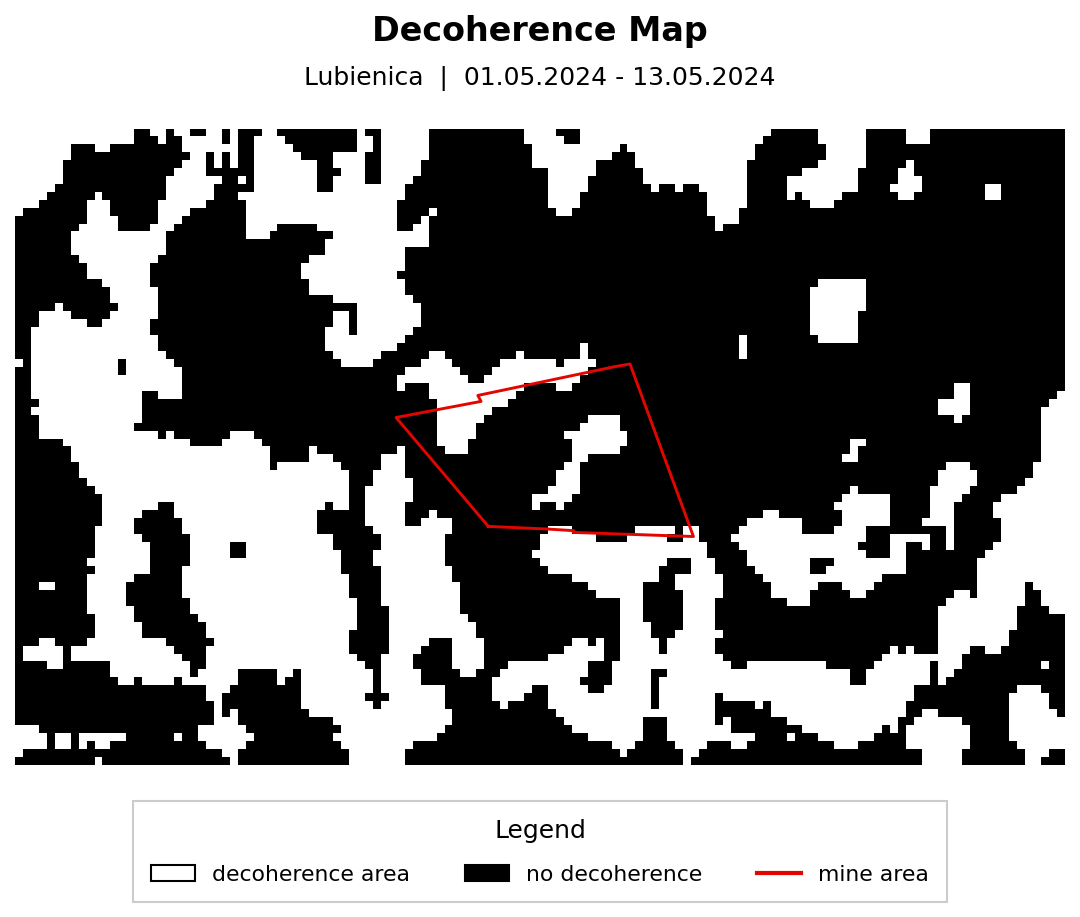

Searching for Sentinel-2 images ...
  date range: 2024-04-01 - 2024-04-30
  images found: 24
  reject: 2024-04-01 20240401T095031_20240401T095543_T34UED, clouds cover AOI
  reject: 2024-04-01 20240401T095031_20240401T095543_T34UDD, clouds cover AOI
  reject: 2024-04-03 20240403T093549_20240403T093703_T34UED, clouds cover AOI
  reject: 2024-04-03 20240403T093549_20240403T093703_T34UDD, clouds cover AOI
  reject: 2024-04-06 20240406T094549_20240406T094713_T34UED, clouds cover AOI
  reject: 2024-04-06 20240406T094549_20240406T094713_T34UDD, clouds cover AOI
  reject: 2024-04-08 20240408T094031_20240408T094030_T34UED, clouds cover AOI
  reject: 2024-04-08 20240408T094031_20240408T094030_T34UDD, clouds cover AOI
  reject: 2024-04-11 20240411T095031_20240411T095129_T34UED, clouds cover AOI
  reject: 2024-04-11 20240411T095031_20240411T095129_T34UDD, clouds cover AOI
  reject: 2024-04-13 20240413T093549_20240413T093836_T34UED, clouds cover AOI
  reject: 2024-04-13 20240413T093549_20240413T093

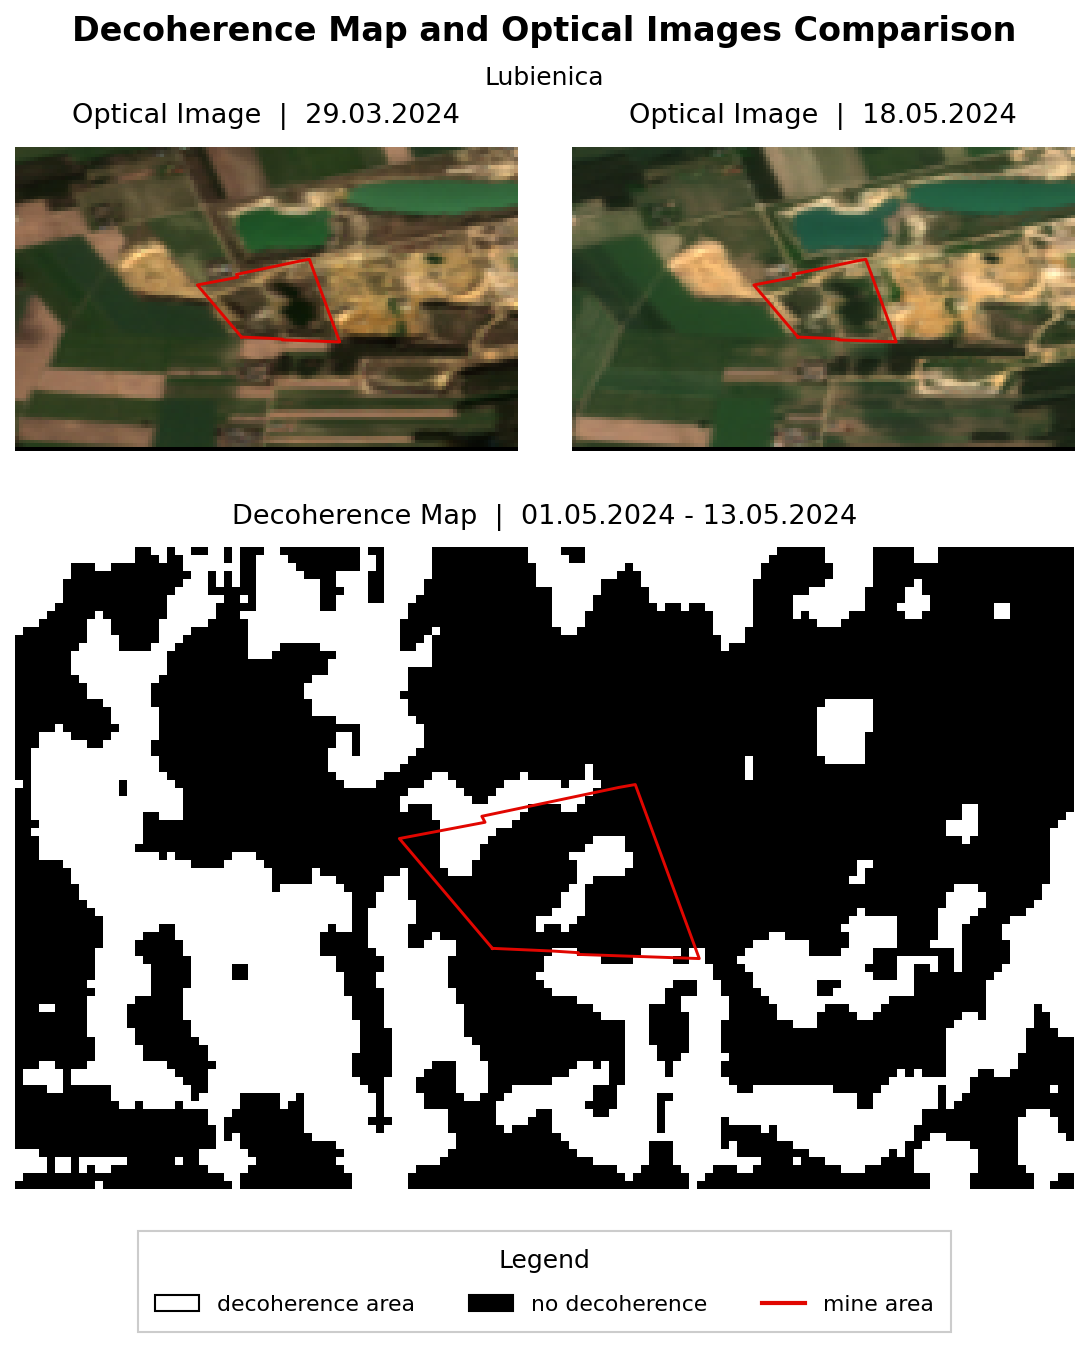

Download: S1A_IW_SLC__1SDV_20240525T045248_20240525T045315_054023_069160_2045.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20240525T045248_20240525T045315_054023_069160_2045.zip (8.27 GB)
Pair 2/17  S1A_IW_SLC__1SDV_20240513T045248_20240513T045315_053848_068B5B_D1CD.zip  x  S1A_IW_SLC__1SDV_20240525T045248_20240525T045315_054023_069160_2045.zip
Opening:  S1A_IW_SLC__1SDV_20240513T045248_20240513T045315_053848_068B5B_D1CD
Opening:  S1A_IW_SLC__1SDV_20240525T045248_20240525T045315_054023_069160_2045
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler Te

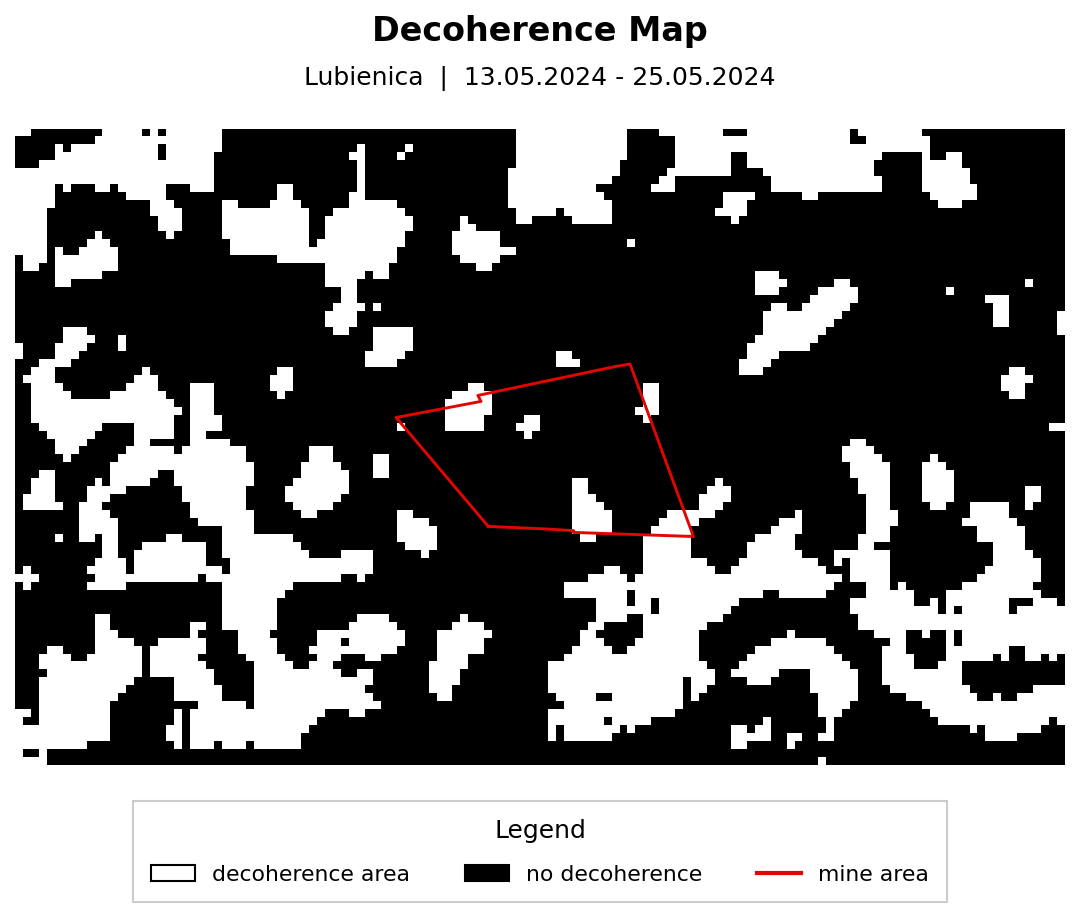

Searching for Sentinel-2 images ...
  date range: 2024-04-13 - 2024-05-12
  images found: 24
  reject: 2024-04-13 20240413T093549_20240413T093836_T34UED, clouds cover AOI
  reject: 2024-04-13 20240413T093549_20240413T093836_T34UDD, clouds cover AOI
  reject: 2024-04-16 20240416T094549_20240416T094759_T34UED, clouds cover AOI
  reject: 2024-04-16 20240416T094549_20240416T094759_T34UDD, clouds cover AOI
  reject: 2024-04-18 20240418T094031_20240418T094034_T34UED, clouds cover AOI
  reject: 2024-04-18 20240418T094031_20240418T094034_T34UDD, clouds cover AOI
  reject: 2024-04-21 20240421T095031_20240421T095031_T34UED, clouds cover AOI
  reject: 2024-04-21 20240421T095031_20240421T095031_T34UDD, clouds cover AOI
  reject: 2024-04-23 20240423T093549_20240423T093835_T34UED, clouds cover AOI
  reject: 2024-04-23 20240423T093549_20240423T093835_T34UDD, clouds cover AOI
  reject: 2024-04-26 20240426T094549_20240426T094757_T34UED, clouds cover AOI
  reject: 2024-04-26 20240426T094549_20240426T094

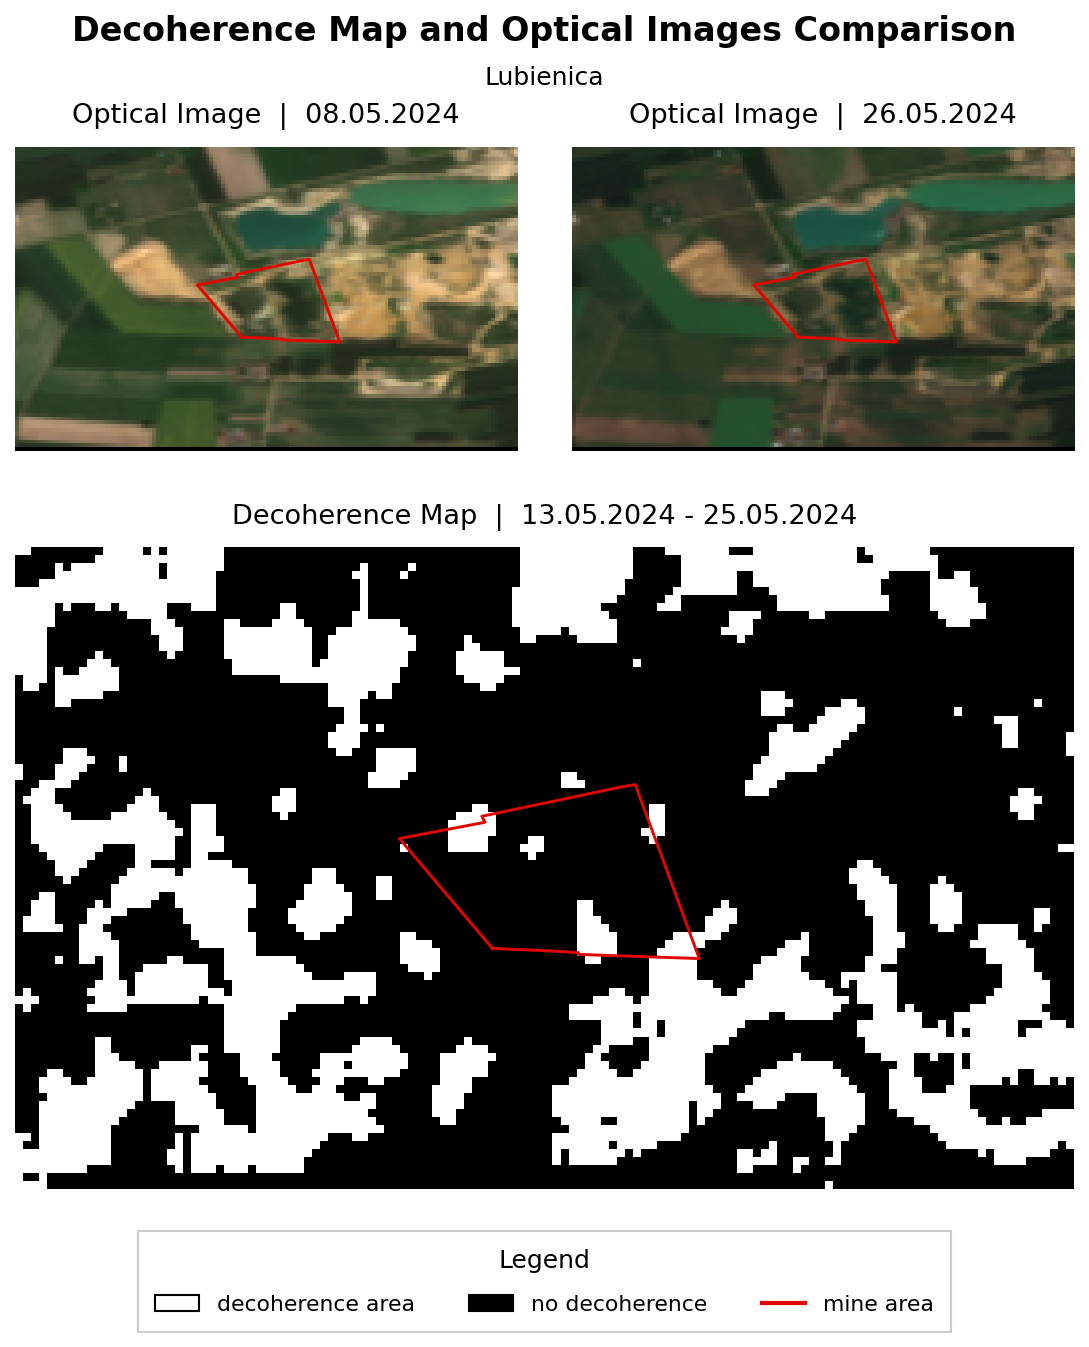

Download: S1A_IW_SLC__1SDV_20240606T045247_20240606T045314_054198_069769_2BB9.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20240606T045247_20240606T045314_054198_069769_2BB9.zip (8.27 GB)
Pair 3/17  S1A_IW_SLC__1SDV_20240525T045248_20240525T045315_054023_069160_2045.zip  x  S1A_IW_SLC__1SDV_20240606T045247_20240606T045314_054198_069769_2BB9.zip
Opening:  S1A_IW_SLC__1SDV_20240525T045248_20240525T045315_054023_069160_2045
Opening:  S1A_IW_SLC__1SDV_20240606T045247_20240606T045314_054198_069769_2BB9
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler Te

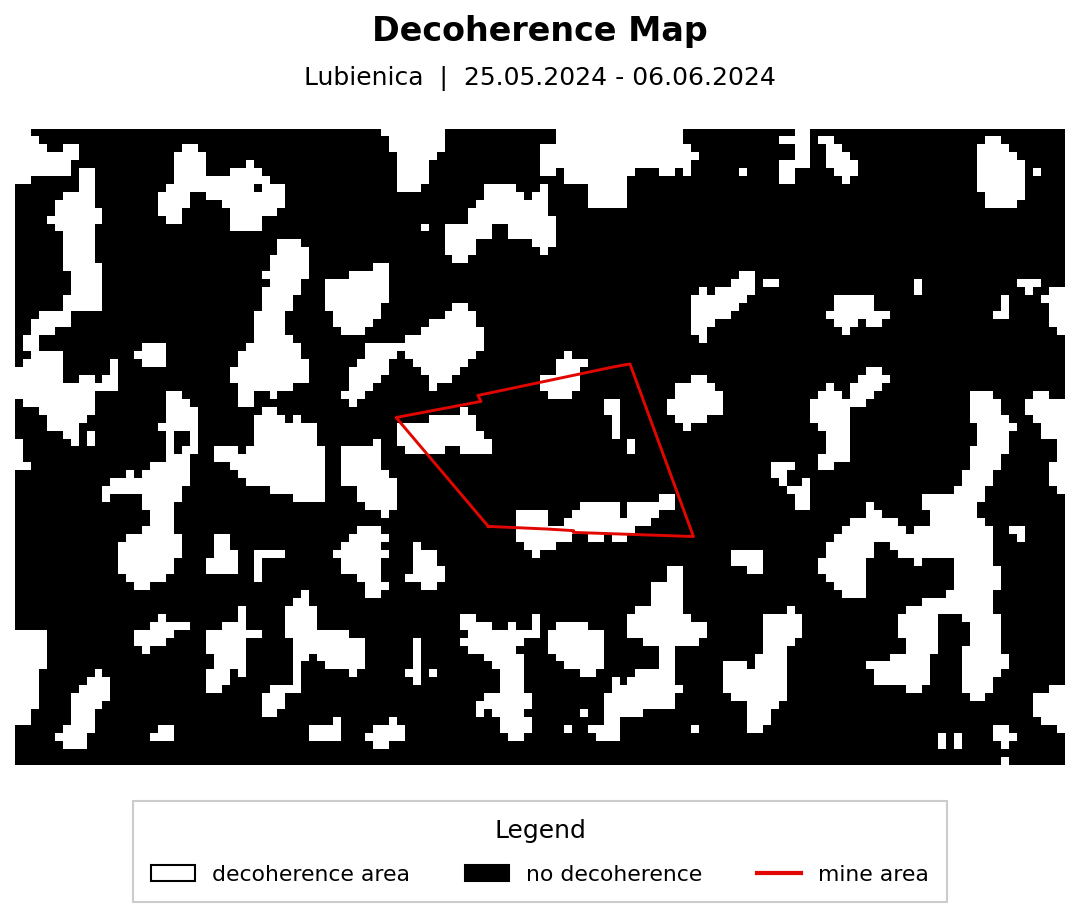

Searching for Sentinel-2 images ...
  date range: 2024-04-25 - 2024-05-24
  images found: 24
  reject: 2024-04-26 20240426T094549_20240426T094757_T34UED, clouds cover AOI
  reject: 2024-04-26 20240426T094549_20240426T094757_T34UDD, clouds cover AOI
  reject: 2024-04-28 20240428T094031_20240428T094033_T34UED, clouds cover AOI
  reject: 2024-04-28 20240428T094031_20240428T094033_T34UDD, clouds cover AOI
  accept: 2024-05-01 20240501T095031_20240501T095031_T34UED
  accept: 2024-05-01 20240501T095031_20240501T095031_T34UDD
  reject: 2024-05-03 20240503T093549_20240503T093836_T34UED, clouds cover AOI
  reject: 2024-05-03 20240503T093549_20240503T093836_T34UDD, clouds cover AOI
  reject: 2024-05-06 20240506T094549_20240506T094716_T34UED, clouds cover AOI
  reject: 2024-05-06 20240506T094549_20240506T094716_T34UDD, clouds cover AOI
  reject: 2024-05-08 20240508T094031_20240508T094038_T34UED, clouds cover AOI
  accept: 2024-05-08 20240508T094031_20240508T094038_T34UDD
  reject: 2024-05-11 2024

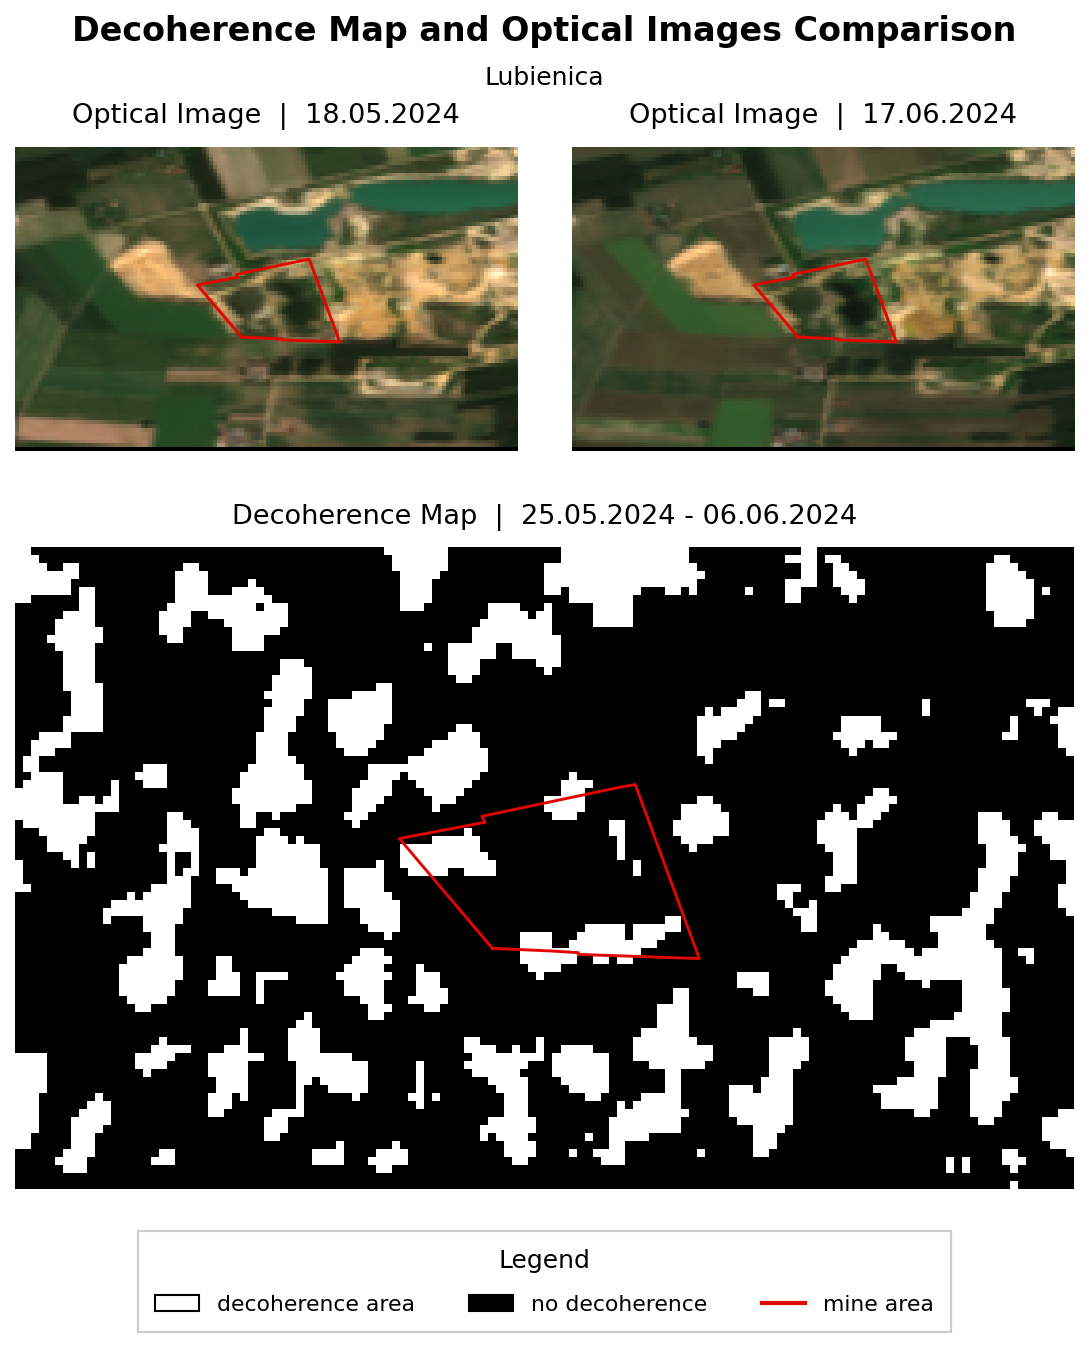

Download: S1A_IW_SLC__1SDV_20240618T045247_20240618T045314_054373_069D75_FCE9.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20240618T045247_20240618T045314_054373_069D75_FCE9.zip (8.27 GB)
Pair 4/17  S1A_IW_SLC__1SDV_20240606T045247_20240606T045314_054198_069769_2BB9.zip  x  S1A_IW_SLC__1SDV_20240618T045247_20240618T045314_054373_069D75_FCE9.zip
Opening:  S1A_IW_SLC__1SDV_20240606T045247_20240606T045314_054198_069769_2BB9
Opening:  S1A_IW_SLC__1SDV_20240618T045247_20240618T045314_054373_069D75_FCE9
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler Te

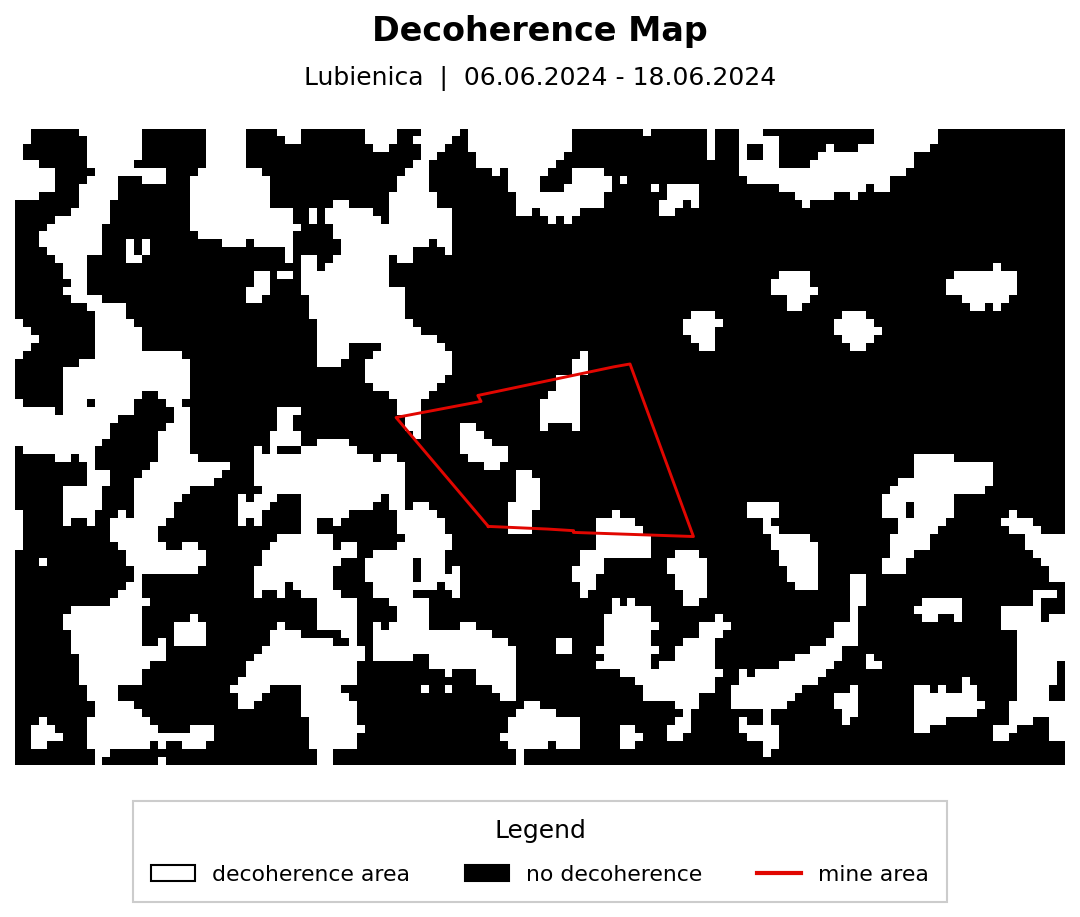

Searching for Sentinel-2 images ...
  date range: 2024-05-06 - 2024-06-05
  images found: 28
  reject: 2024-05-06 20240506T094549_20240506T094716_T34UED, clouds cover AOI
  reject: 2024-05-06 20240506T094549_20240506T094716_T34UDD, clouds cover AOI
  reject: 2024-05-08 20240508T094031_20240508T094038_T34UED, clouds cover AOI
  accept: 2024-05-08 20240508T094031_20240508T094038_T34UDD
  reject: 2024-05-11 20240511T095031_20240511T095031_T34UED, clouds cover AOI
  reject: 2024-05-11 20240511T095031_20240511T095031_T34UDD, clouds cover AOI
  accept: 2024-05-13 20240513T093549_20240513T093835_T34UED
  accept: 2024-05-13 20240513T093549_20240513T093835_T34UDD
  reject: 2024-05-16 20240516T094549_20240516T094756_T34UED, clouds cover AOI
  reject: 2024-05-16 20240516T094549_20240516T094756_T34UDD, clouds cover AOI
  accept: 2024-05-18 20240518T094031_20240518T094032_T34UED
  accept: 2024-05-18 20240518T094031_20240518T094032_T34UDD
  reject: 2024-05-21 20240521T095031_20240521T095028_T34UED, 

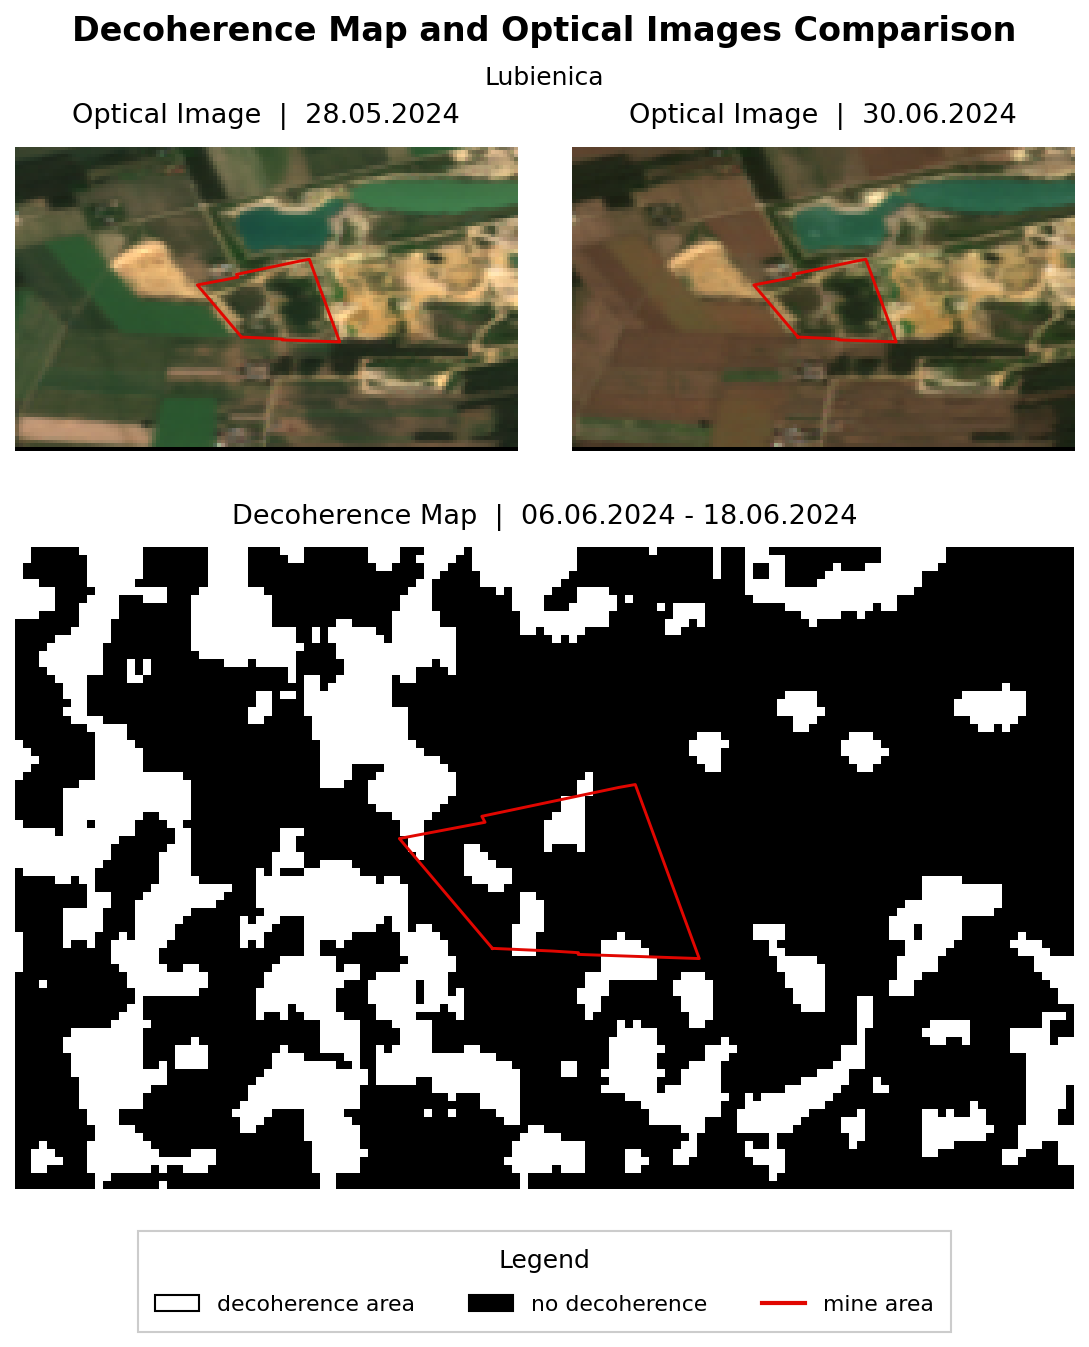

Download: S1A_IW_SLC__1SDV_20240630T045243_20240630T045315_054548_06A38A_42A7.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20240630T045243_20240630T045315_054548_06A38A_42A7.zip (5.68 GB)
Pair 5/17  S1A_IW_SLC__1SDV_20240618T045247_20240618T045314_054373_069D75_FCE9.zip  x  S1A_IW_SLC__1SDV_20240630T045243_20240630T045315_054548_06A38A_42A7.zip
Opening:  S1A_IW_SLC__1SDV_20240618T045247_20240618T045314_054373_069D75_FCE9
Opening:  S1A_IW_SLC__1SDV_20240630T045243_20240630T045315_054548_06A38A_42A7
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler Te

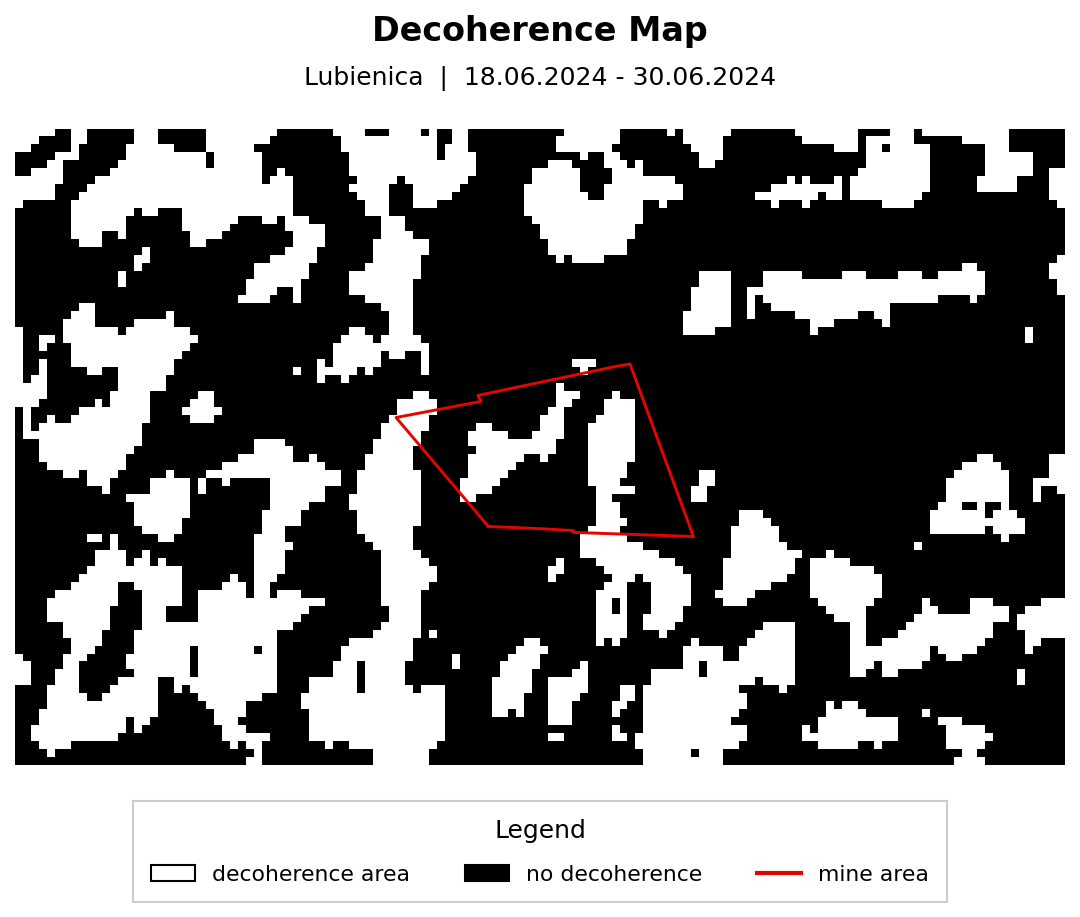

Searching for Sentinel-2 images ...
  date range: 2024-05-18 - 2024-06-17
  images found: 28
  accept: 2024-05-18 20240518T094031_20240518T094032_T34UED
  accept: 2024-05-18 20240518T094031_20240518T094032_T34UDD
  reject: 2024-05-21 20240521T095031_20240521T095028_T34UED, clouds cover AOI
  reject: 2024-05-21 20240521T095031_20240521T095028_T34UDD, clouds cover AOI
  reject: 2024-05-23 20240523T093549_20240523T093831_T34UED, clouds cover AOI
  reject: 2024-05-23 20240523T093549_20240523T093831_T34UDD, clouds cover AOI
  accept: 2024-05-26 20240526T094549_20240526T094758_T34UED
  accept: 2024-05-26 20240526T094549_20240526T094758_T34UDD
  accept: 2024-05-28 20240528T094031_20240528T094033_T34UED
  accept: 2024-05-28 20240528T094031_20240528T094033_T34UDD
  reject: 2024-05-31 20240531T095031_20240531T095031_T34UED, clouds cover AOI
  reject: 2024-05-31 20240531T095031_20240531T095031_T34UDD, clouds cover AOI
  reject: 2024-05-31 20240531T095031_20240531T095556_T34UED, clouds cover AOI
 

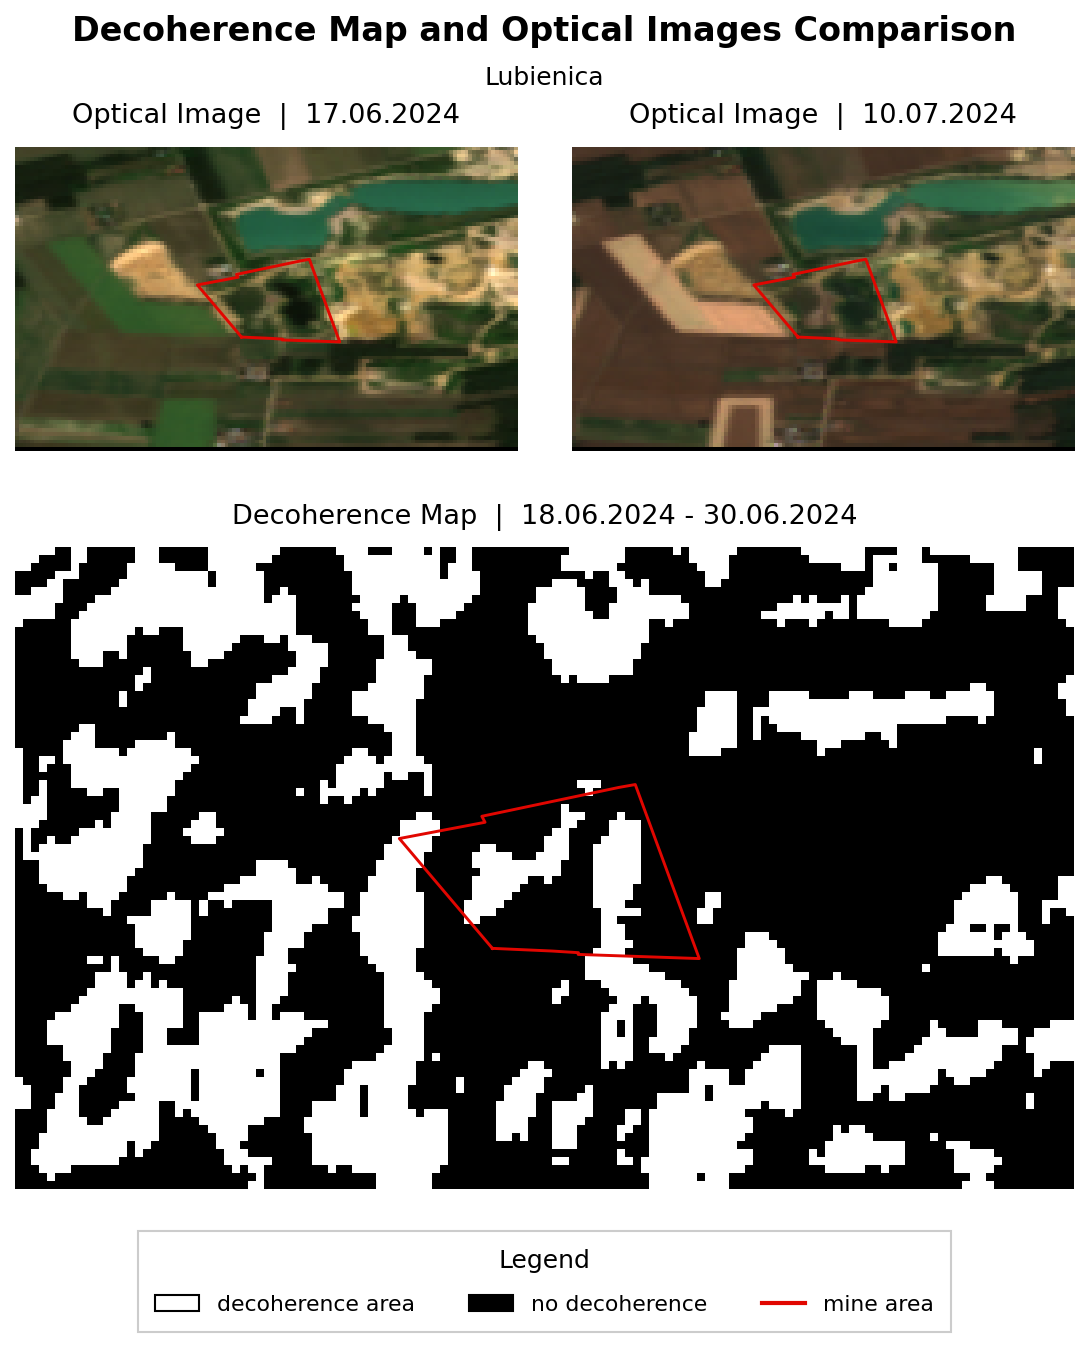

Download: S1A_IW_SLC__1SDV_20240712T045246_20240712T045313_054723_06A99F_145F.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20240712T045246_20240712T045313_054723_06A99F_145F.zip (4.75 GB)
Pair 6/17  S1A_IW_SLC__1SDV_20240630T045243_20240630T045315_054548_06A38A_42A7.zip  x  S1A_IW_SLC__1SDV_20240712T045246_20240712T045313_054723_06A99F_145F.zip
Opening:  S1A_IW_SLC__1SDV_20240630T045243_20240630T045315_054548_06A38A_42A7
Opening:  S1A_IW_SLC__1SDV_20240712T045246_20240712T045313_054723_06A99F_145F
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler Te

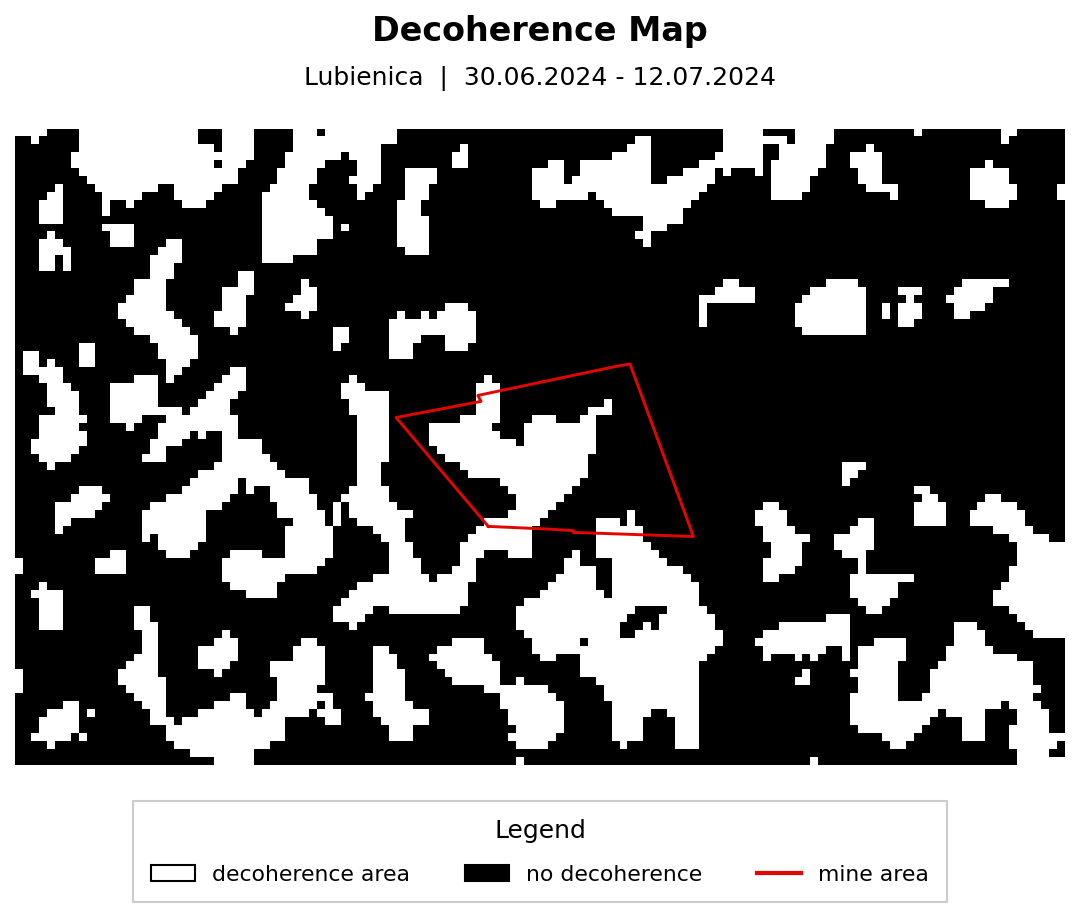

Searching for Sentinel-2 images ...
  date range: 2024-05-30 - 2024-06-29
  images found: 26
  reject: 2024-05-31 20240531T095031_20240531T095031_T34UED, clouds cover AOI
  reject: 2024-05-31 20240531T095031_20240531T095031_T34UDD, clouds cover AOI
  reject: 2024-05-31 20240531T095031_20240531T095556_T34UED, clouds cover AOI
  reject: 2024-05-31 20240531T095031_20240531T095556_T34UDD, clouds cover AOI
  reject: 2024-06-02 20240602T093549_20240602T093833_T34UED, clouds cover AOI
  reject: 2024-06-02 20240602T093549_20240602T093833_T34UDD, clouds cover AOI
  reject: 2024-06-05 20240605T094549_20240605T094757_T34UED, clouds cover AOI
  reject: 2024-06-05 20240605T094549_20240605T094757_T34UDD, clouds cover AOI
  reject: 2024-06-07 20240607T094041_20240607T094036_T34UED, clouds cover AOI
  reject: 2024-06-07 20240607T094041_20240607T094036_T34UDD, clouds cover AOI
  reject: 2024-06-10 20240610T095031_20240610T095034_T34UED, clouds cover AOI
  reject: 2024-06-10 20240610T095031_20240610T095

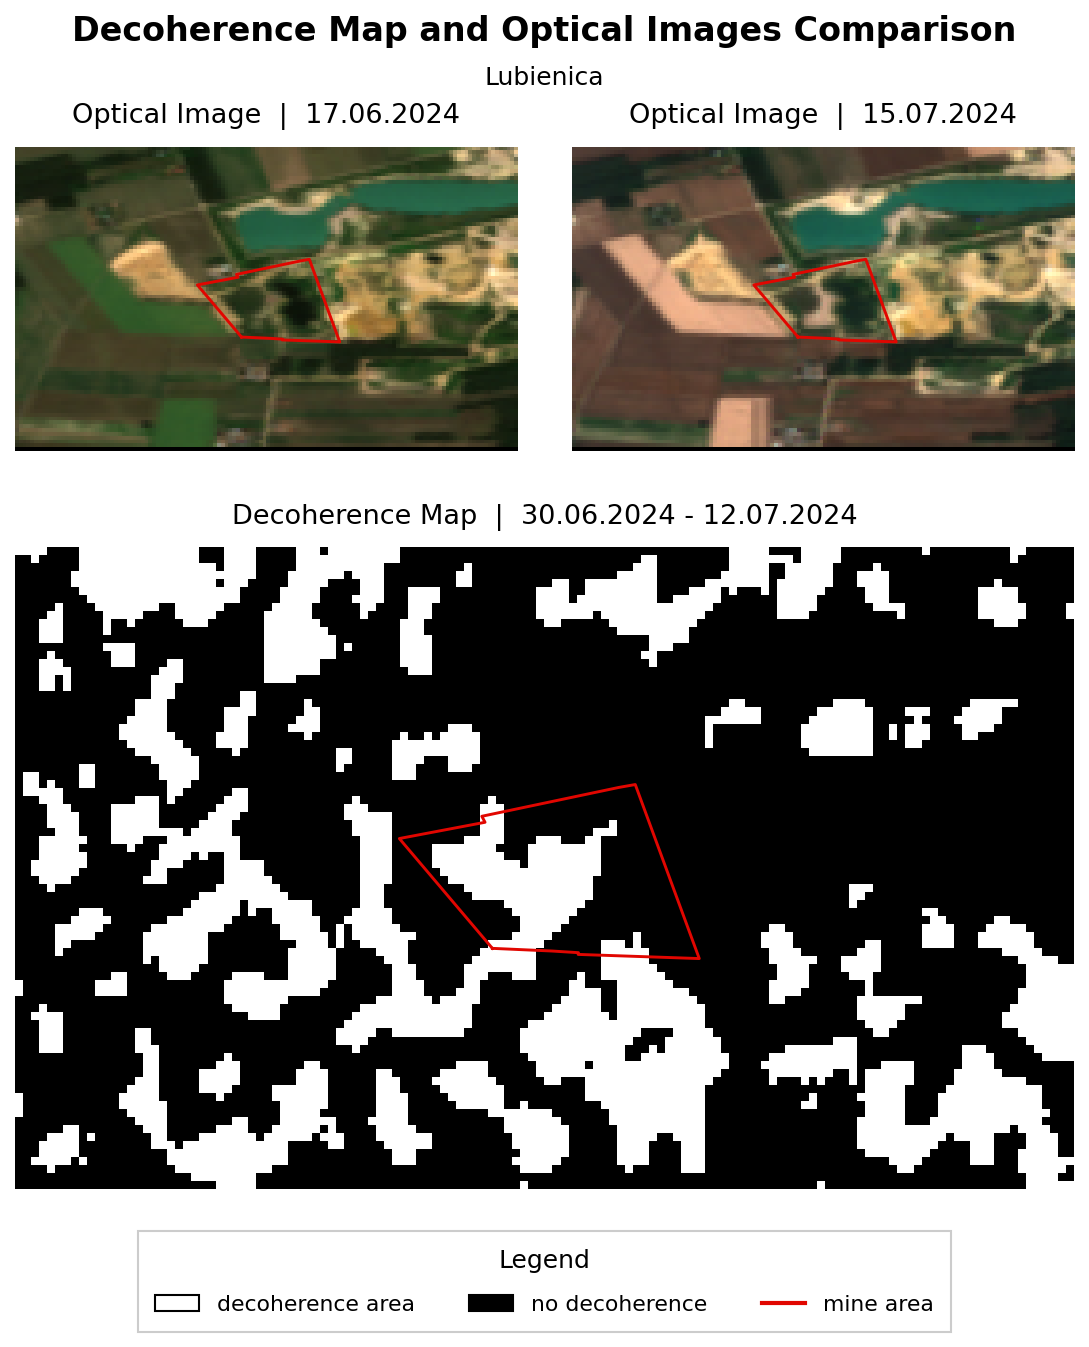

Download: S1A_IW_SLC__1SDV_20240724T045245_20240724T045312_054898_06AFB5_B749.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20240724T045245_20240724T045312_054898_06AFB5_B749.zip (4.64 GB)
Pair 7/17  S1A_IW_SLC__1SDV_20240712T045246_20240712T045313_054723_06A99F_145F.zip  x  S1A_IW_SLC__1SDV_20240724T045245_20240724T045312_054898_06AFB5_B749.zip
Opening:  S1A_IW_SLC__1SDV_20240712T045246_20240712T045313_054723_06A99F_145F
Opening:  S1A_IW_SLC__1SDV_20240724T045245_20240724T045312_054898_06AFB5_B749
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler Te

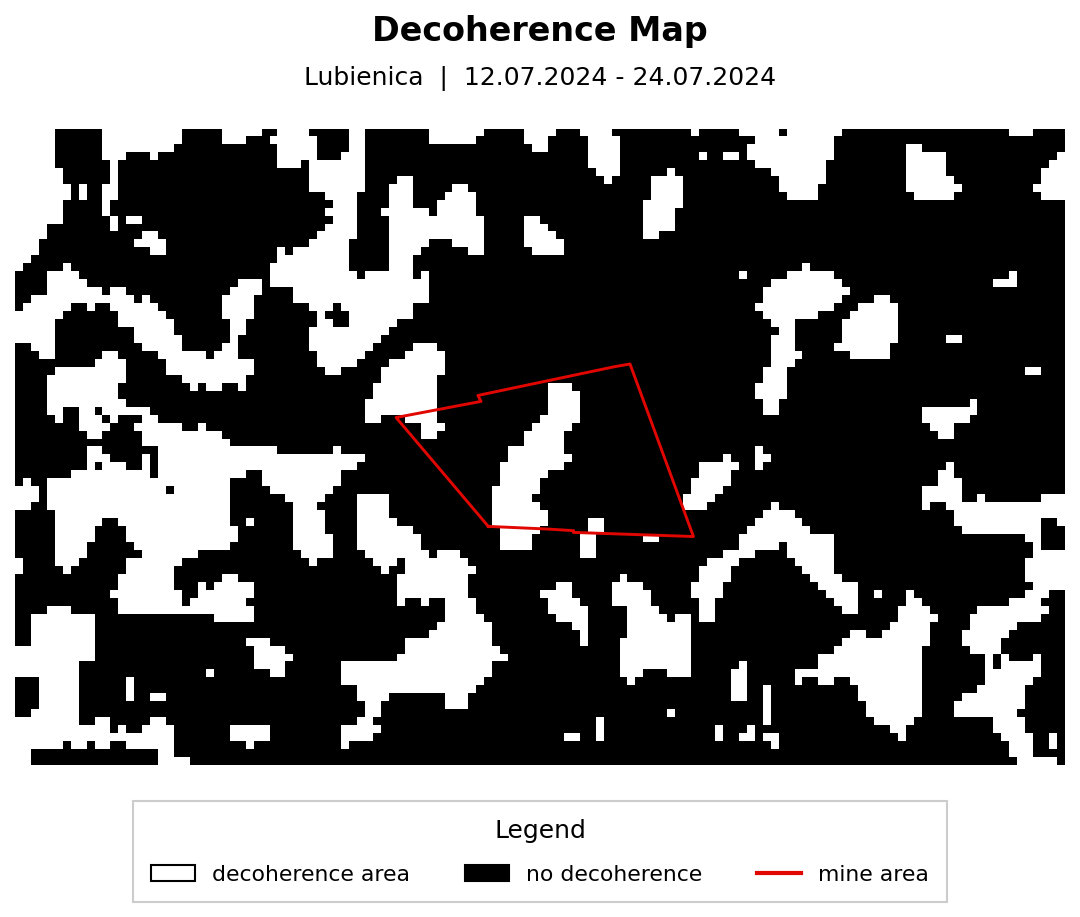

Searching for Sentinel-2 images ...
  date range: 2024-06-12 - 2024-07-11
  images found: 24
  reject: 2024-06-12 20240612T093549_20240612T093737_T34UED, clouds cover AOI
  reject: 2024-06-12 20240612T093549_20240612T093737_T34UDD, clouds cover AOI
  reject: 2024-06-15 20240615T094549_20240615T094801_T34UED, clouds cover AOI
  reject: 2024-06-15 20240615T094549_20240615T094801_T34UDD, clouds cover AOI
  accept: 2024-06-17 20240617T094041_20240617T094036_T34UED
  accept: 2024-06-17 20240617T094041_20240617T094036_T34UDD
  reject: 2024-06-20 20240620T095031_20240620T095033_T34UED, clouds cover AOI
  reject: 2024-06-20 20240620T095031_20240620T095033_T34UDD, clouds cover AOI
  reject: 2024-06-22 20240622T093549_20240622T093834_T34UED, clouds cover AOI
  reject: 2024-06-22 20240622T093549_20240622T093834_T34UDD, clouds cover AOI
  reject: 2024-06-25 20240625T094549_20240625T094758_T34UED, clouds cover AOI
  reject: 2024-06-25 20240625T094549_20240625T094758_T34UDD, clouds cover AOI
  rejec

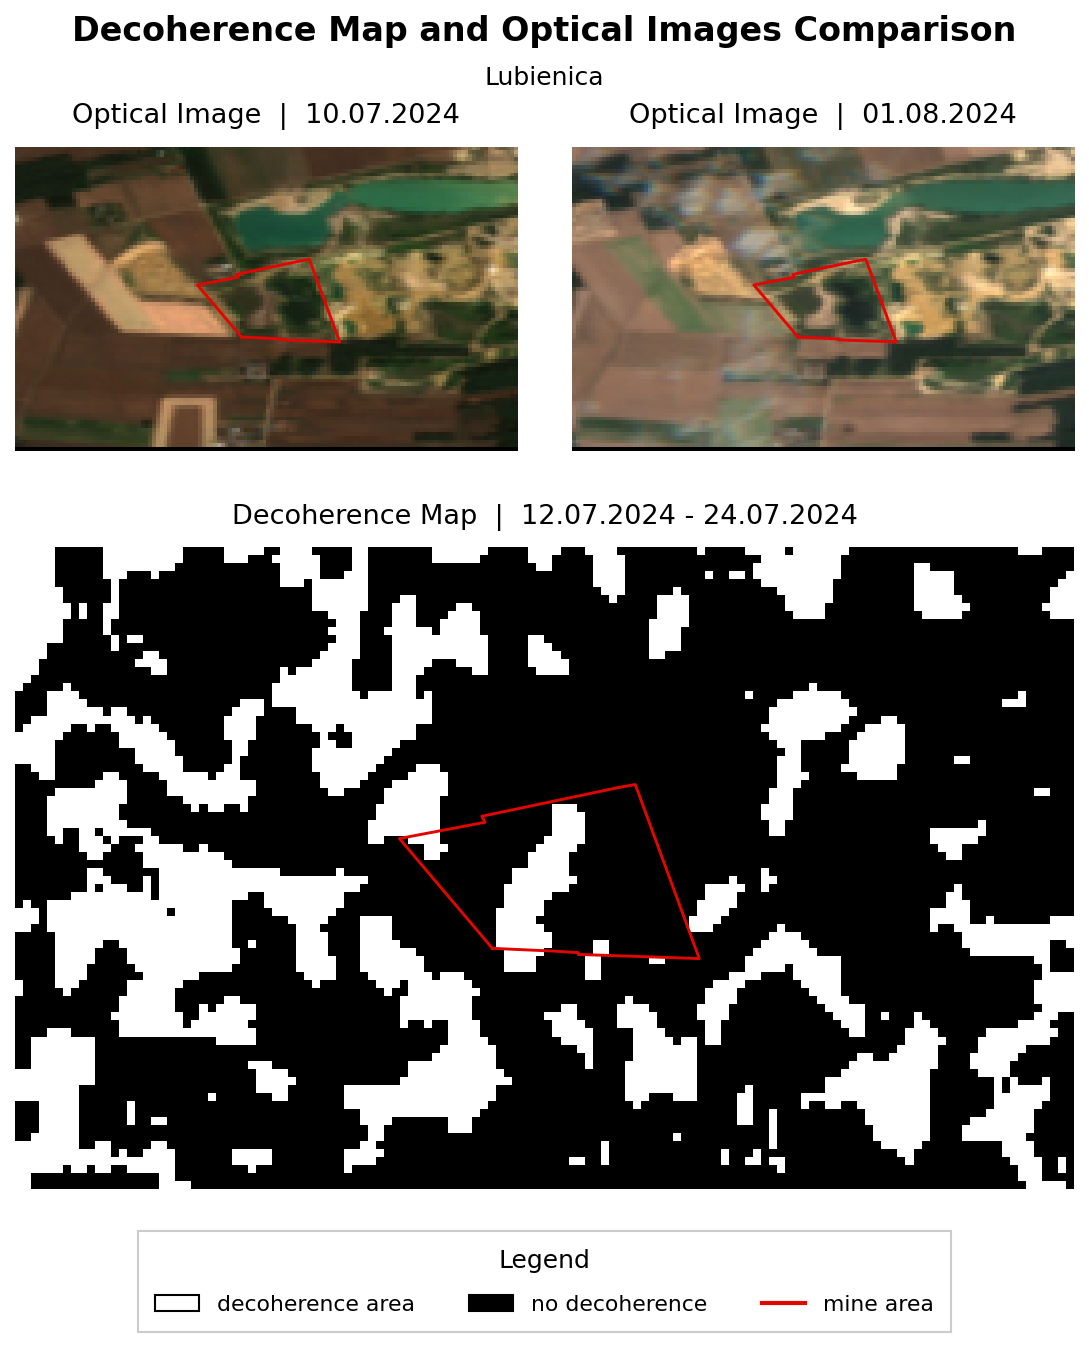

Download: S1A_IW_SLC__1SDV_20240805T045246_20240805T045313_055073_06B5B1_78C2.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20240805T045246_20240805T045313_055073_06B5B1_78C2.zip (4.71 GB)
Pair 8/17  S1A_IW_SLC__1SDV_20240724T045245_20240724T045312_054898_06AFB5_B749.zip  x  S1A_IW_SLC__1SDV_20240805T045246_20240805T045313_055073_06B5B1_78C2.zip
Opening:  S1A_IW_SLC__1SDV_20240724T045245_20240724T045312_054898_06AFB5_B749
Opening:  S1A_IW_SLC__1SDV_20240805T045246_20240805T045313_055073_06B5B1_78C2
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler Te

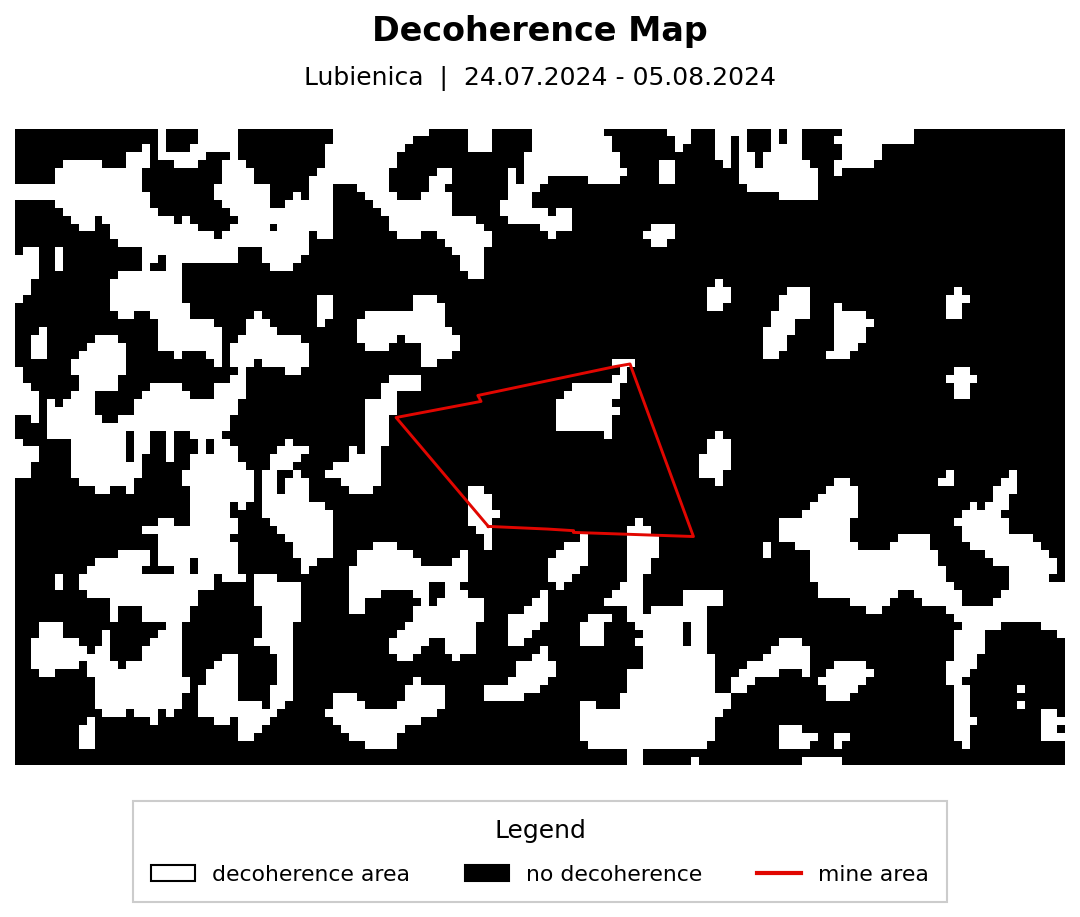

Searching for Sentinel-2 images ...
  date range: 2024-06-24 - 2024-07-23
  images found: 24
  reject: 2024-06-25 20240625T094549_20240625T094758_T34UED, clouds cover AOI
  reject: 2024-06-25 20240625T094549_20240625T094758_T34UDD, clouds cover AOI
  reject: 2024-06-27 20240627T094031_20240627T094033_T34UED, clouds cover AOI
  reject: 2024-06-27 20240627T094031_20240627T094033_T34UDD, clouds cover AOI
  accept: 2024-06-30 20240630T095031_20240630T095031_T34UED
  accept: 2024-06-30 20240630T095031_20240630T095031_T34UDD
  reject: 2024-07-02 20240702T093549_20240702T093549_T34UED, clouds cover AOI
  reject: 2024-07-02 20240702T093549_20240702T093549_T34UDD, clouds cover AOI
  reject: 2024-07-05 20240705T094549_20240705T094718_T34UED, clouds cover AOI
  reject: 2024-07-05 20240705T094549_20240705T094718_T34UDD, clouds cover AOI
  reject: 2024-07-07 20240707T094041_20240707T094035_T34UED, clouds cover AOI
  reject: 2024-07-07 20240707T094041_20240707T094035_T34UDD, clouds cover AOI
  accep

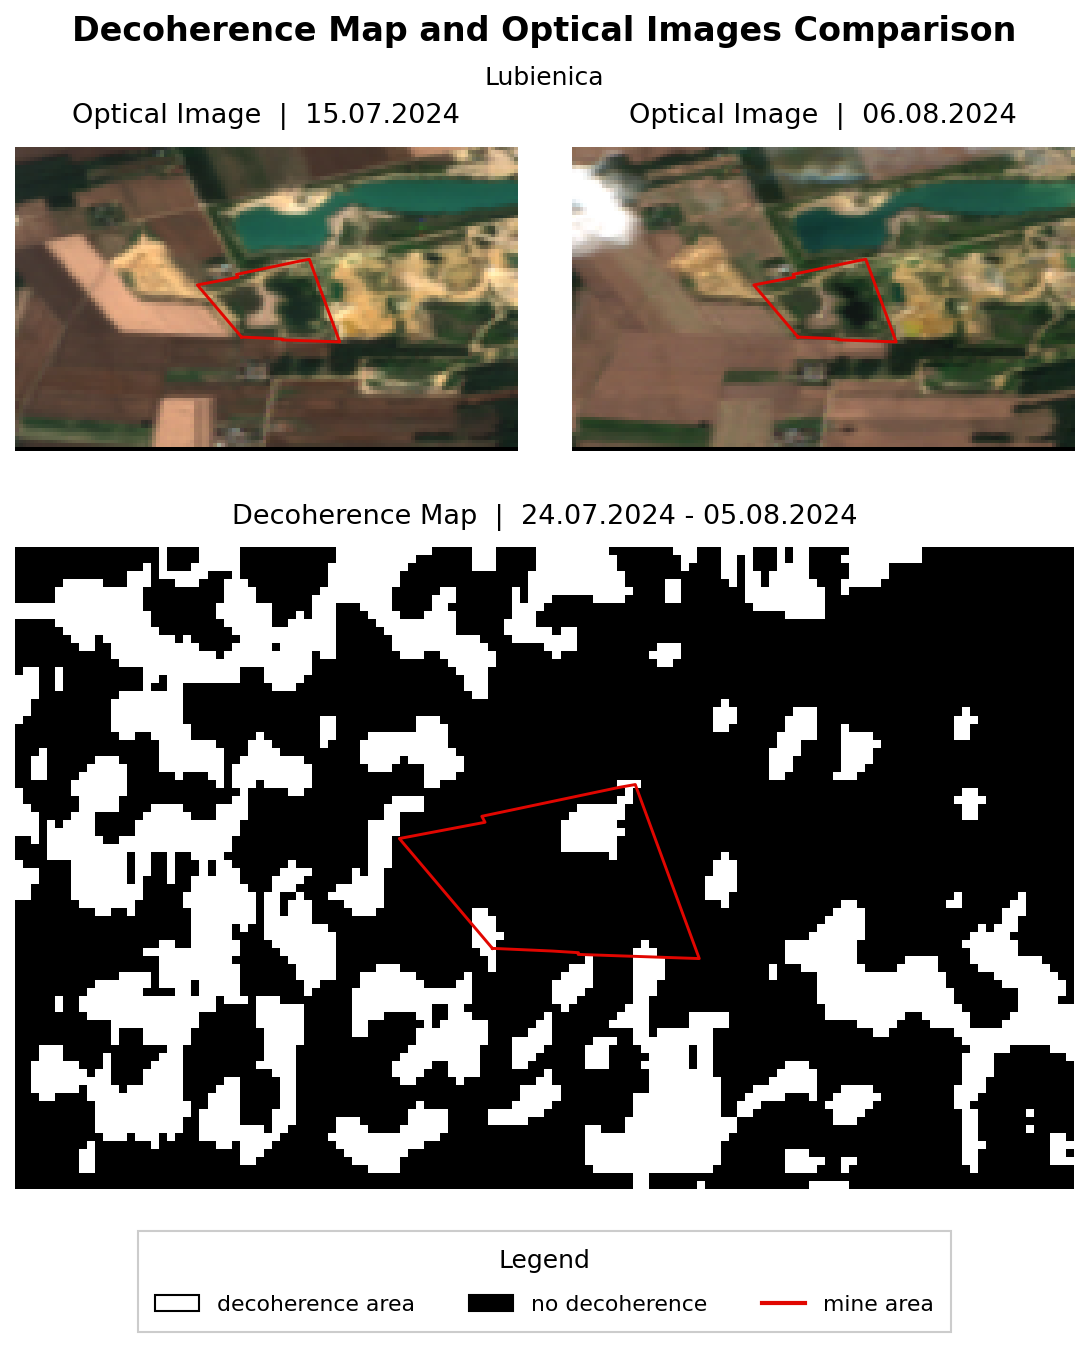

Download: S1A_IW_SLC__1SDV_20240817T045245_20240817T045312_055248_06BC15_285C.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20240817T045245_20240817T045312_055248_06BC15_285C.zip (4.63 GB)
Pair 9/17  S1A_IW_SLC__1SDV_20240805T045246_20240805T045313_055073_06B5B1_78C2.zip  x  S1A_IW_SLC__1SDV_20240817T045245_20240817T045312_055248_06BC15_285C.zip
Opening:  S1A_IW_SLC__1SDV_20240805T045246_20240805T045313_055073_06B5B1_78C2
Opening:  S1A_IW_SLC__1SDV_20240817T045245_20240817T045312_055248_06BC15_285C
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler Te

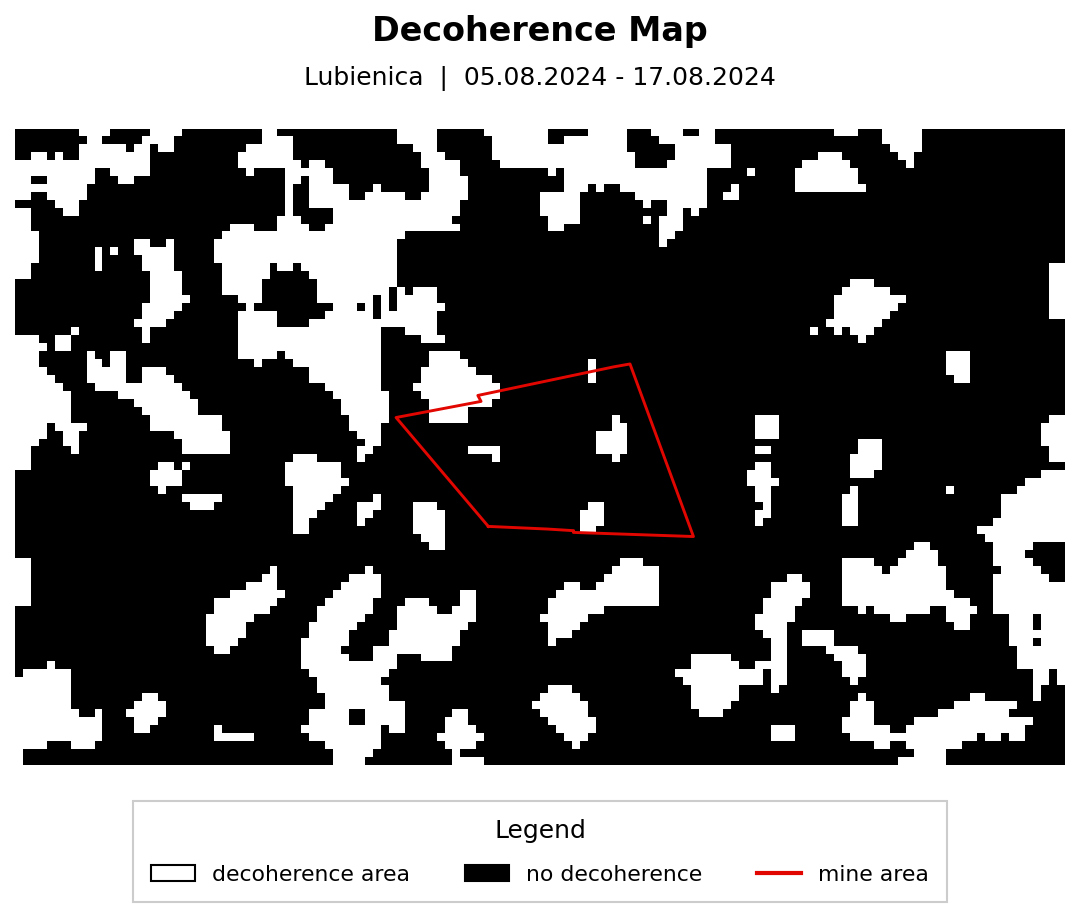

Searching for Sentinel-2 images ...
  date range: 2024-07-05 - 2024-08-04
  images found: 26
  reject: 2024-07-05 20240705T094549_20240705T094718_T34UED, clouds cover AOI
  reject: 2024-07-05 20240705T094549_20240705T094718_T34UDD, clouds cover AOI
  reject: 2024-07-07 20240707T094041_20240707T094035_T34UED, clouds cover AOI
  reject: 2024-07-07 20240707T094041_20240707T094035_T34UDD, clouds cover AOI
  accept: 2024-07-10 20240710T095031_20240710T095042_T34UED
  accept: 2024-07-10 20240710T095031_20240710T095042_T34UDD
  reject: 2024-07-12 20240712T093549_20240712T093838_T34UED, clouds cover AOI
  reject: 2024-07-12 20240712T093549_20240712T093838_T34UDD, clouds cover AOI
  accept: 2024-07-15 20240715T094549_20240715T094801_T34UED
  accept: 2024-07-15 20240715T094549_20240715T094801_T34UDD
  reject: 2024-07-17 20240717T094031_20240717T094032_T34UED, clouds cover AOI
  reject: 2024-07-17 20240717T094031_20240717T094032_T34UDD, clouds cover AOI
  reject: 2024-07-20 20240720T095031_202407

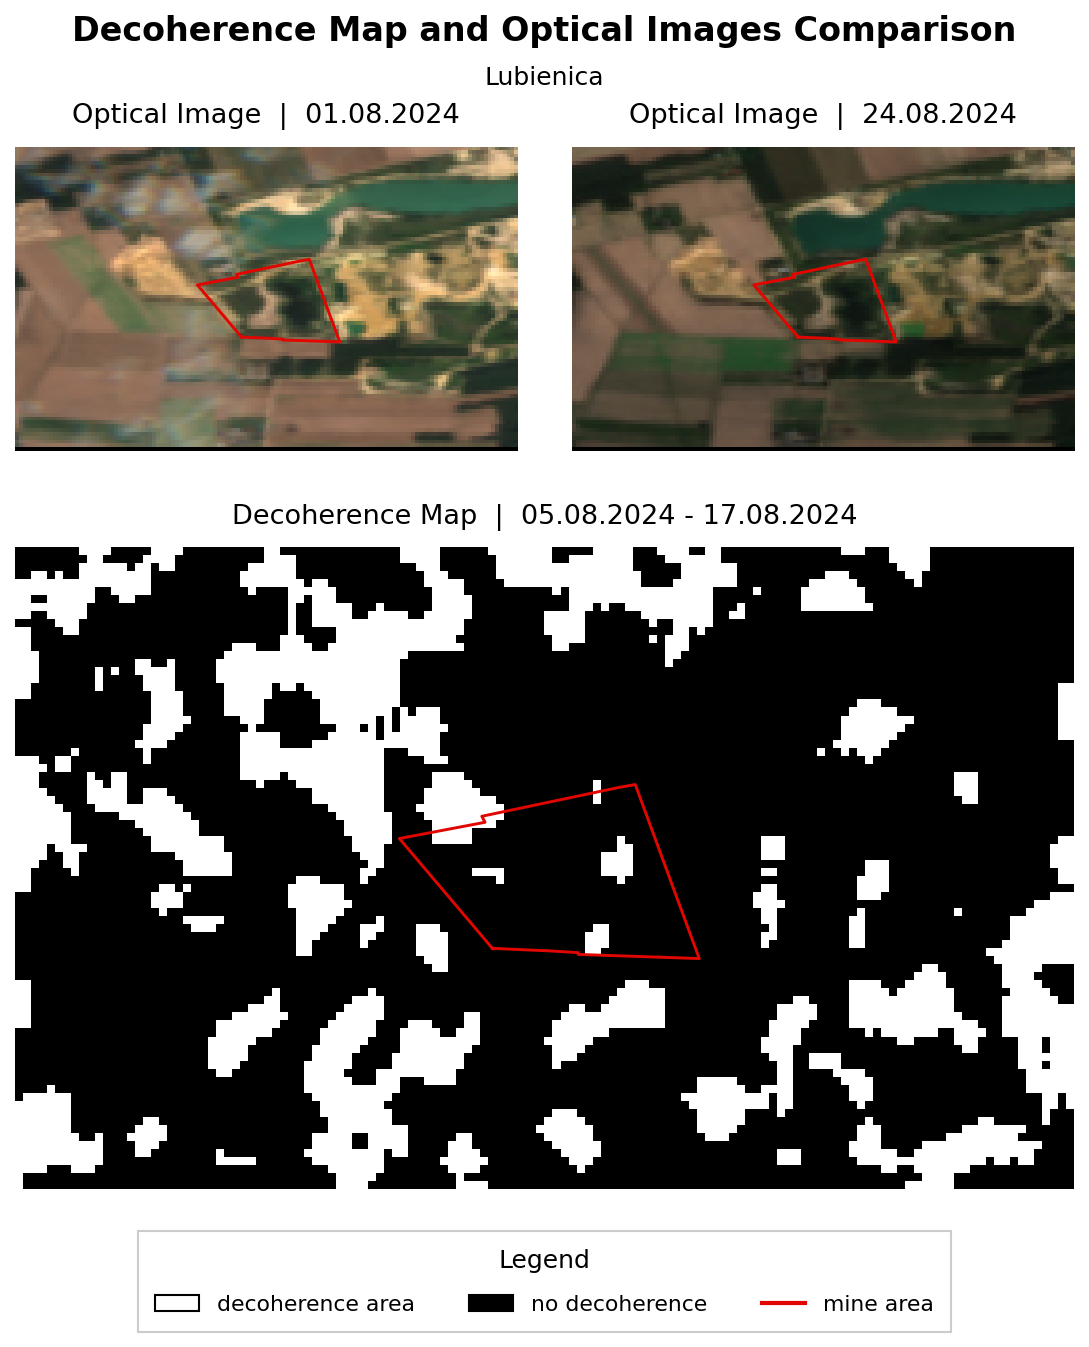

Download: S1A_IW_SLC__1SDV_20240829T045246_20240829T045313_055423_06C28D_8FF7.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20240829T045246_20240829T045313_055423_06C28D_8FF7.zip (4.64 GB)
Pair 10/17  S1A_IW_SLC__1SDV_20240817T045245_20240817T045312_055248_06BC15_285C.zip  x  S1A_IW_SLC__1SDV_20240829T045246_20240829T045313_055423_06C28D_8FF7.zip
Opening:  S1A_IW_SLC__1SDV_20240817T045245_20240817T045312_055248_06BC15_285C
Opening:  S1A_IW_SLC__1SDV_20240829T045246_20240829T045313_055423_06C28D_8FF7
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler T

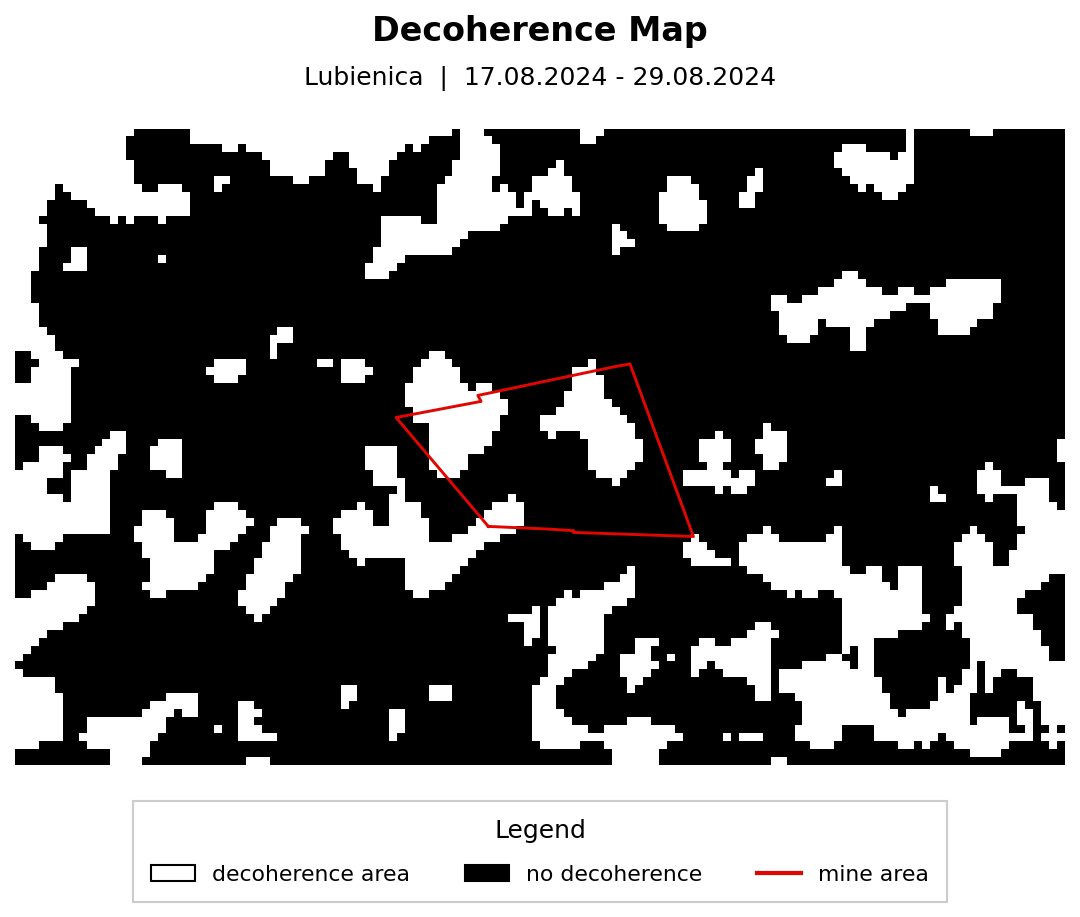

Searching for Sentinel-2 images ...
  date range: 2024-07-17 - 2024-08-16
  images found: 26
  reject: 2024-07-17 20240717T094031_20240717T094032_T34UED, clouds cover AOI
  reject: 2024-07-17 20240717T094031_20240717T094032_T34UDD, clouds cover AOI
  reject: 2024-07-20 20240720T095031_20240720T095029_T34UED, clouds cover AOI
  reject: 2024-07-20 20240720T095031_20240720T095029_T34UDD, clouds cover AOI
  reject: 2024-07-22 20240722T093549_20240722T094244_T34UED, clouds cover AOI
  reject: 2024-07-22 20240722T093549_20240722T094244_T34UDD, clouds cover AOI
  reject: 2024-07-25 20240725T094549_20240725T094801_T34UED, clouds cover AOI
  reject: 2024-07-25 20240725T094549_20240725T094801_T34UDD, clouds cover AOI
  reject: 2024-07-27 20240727T094031_20240727T094033_T34UED, clouds cover AOI
  reject: 2024-07-27 20240727T094031_20240727T094033_T34UDD, clouds cover AOI
  reject: 2024-07-30 20240730T095031_20240730T095149_T34UED, clouds cover AOI
  reject: 2024-07-30 20240730T095031_20240730T095

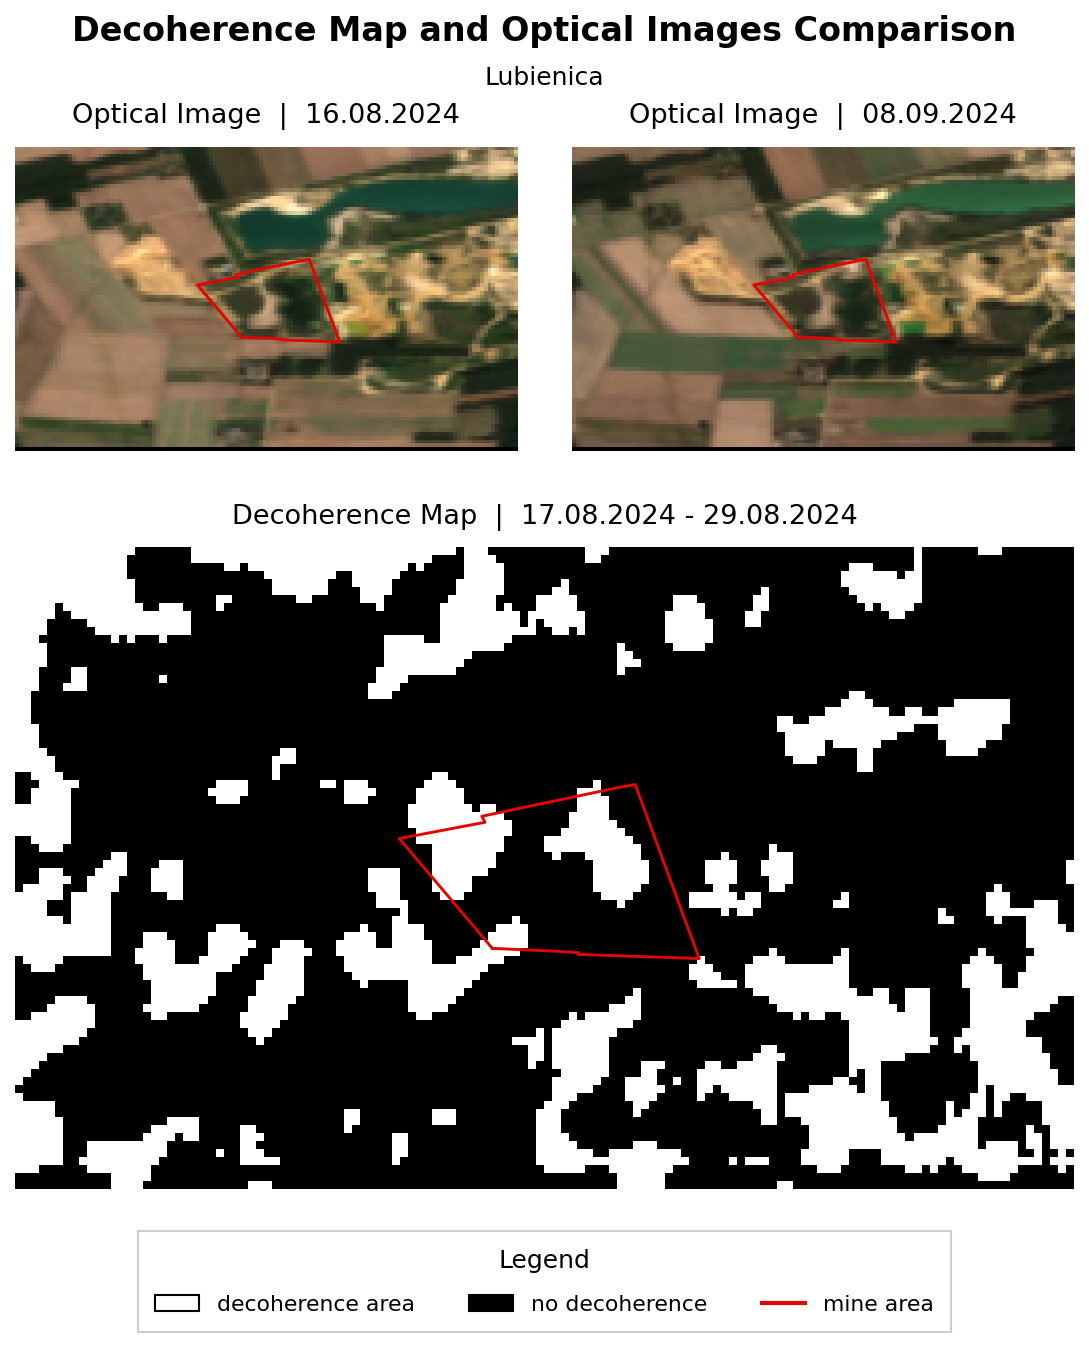

Download: S1A_IW_SLC__1SDV_20240910T045246_20240910T045313_055598_06C964_74ED.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20240910T045246_20240910T045313_055598_06C964_74ED.zip (4.79 GB)
Pair 11/17  S1A_IW_SLC__1SDV_20240829T045246_20240829T045313_055423_06C28D_8FF7.zip  x  S1A_IW_SLC__1SDV_20240910T045246_20240910T045313_055598_06C964_74ED.zip
Opening:  S1A_IW_SLC__1SDV_20240829T045246_20240829T045313_055423_06C28D_8FF7
Opening:  S1A_IW_SLC__1SDV_20240910T045246_20240910T045313_055598_06C964_74ED
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler T

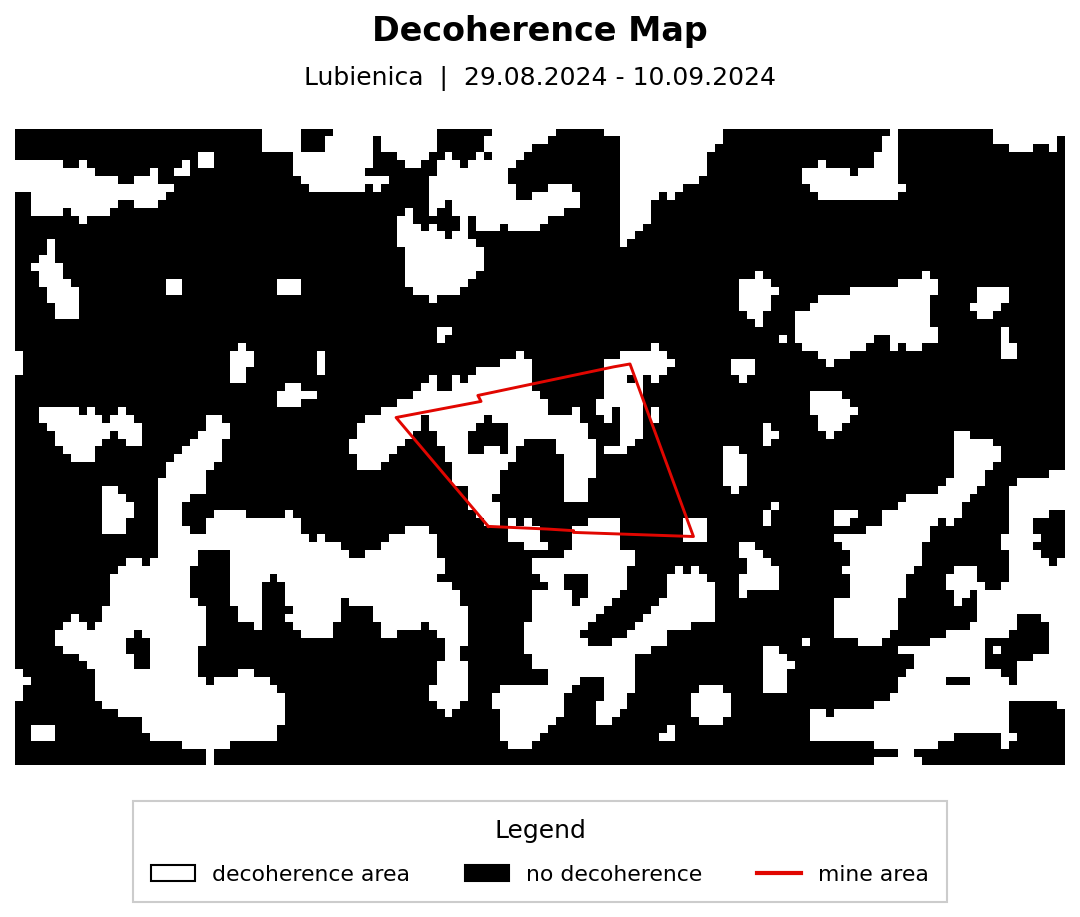

Searching for Sentinel-2 images ...
  date range: 2024-07-29 - 2024-08-28
  images found: 26
  reject: 2024-07-30 20240730T095031_20240730T095149_T34UED, clouds cover AOI
  reject: 2024-07-30 20240730T095031_20240730T095149_T34UDD, clouds cover AOI
  accept: 2024-08-01 20240801T093549_20240801T093836_T34UED
  accept: 2024-08-01 20240801T093549_20240801T093836_T34UDD
  reject: 2024-08-04 20240804T094549_20240804T095007_T34UED, clouds cover AOI
  reject: 2024-08-04 20240804T094549_20240804T095007_T34UDD, clouds cover AOI
  accept: 2024-08-06 20240806T094031_20240806T094438_T34UED
  accept: 2024-08-06 20240806T094031_20240806T094438_T34UDD
  reject: 2024-08-09 20240809T095031_20240809T095347_T34UED, clouds cover AOI
  reject: 2024-08-09 20240809T095031_20240809T095347_T34UDD, clouds cover AOI
  reject: 2024-08-11 20240811T093549_20240811T094151_T34UED, clouds cover AOI
  reject: 2024-08-11 20240811T093549_20240811T094151_T34UDD, clouds cover AOI
  accept: 2024-08-14 20240814T094549_202408

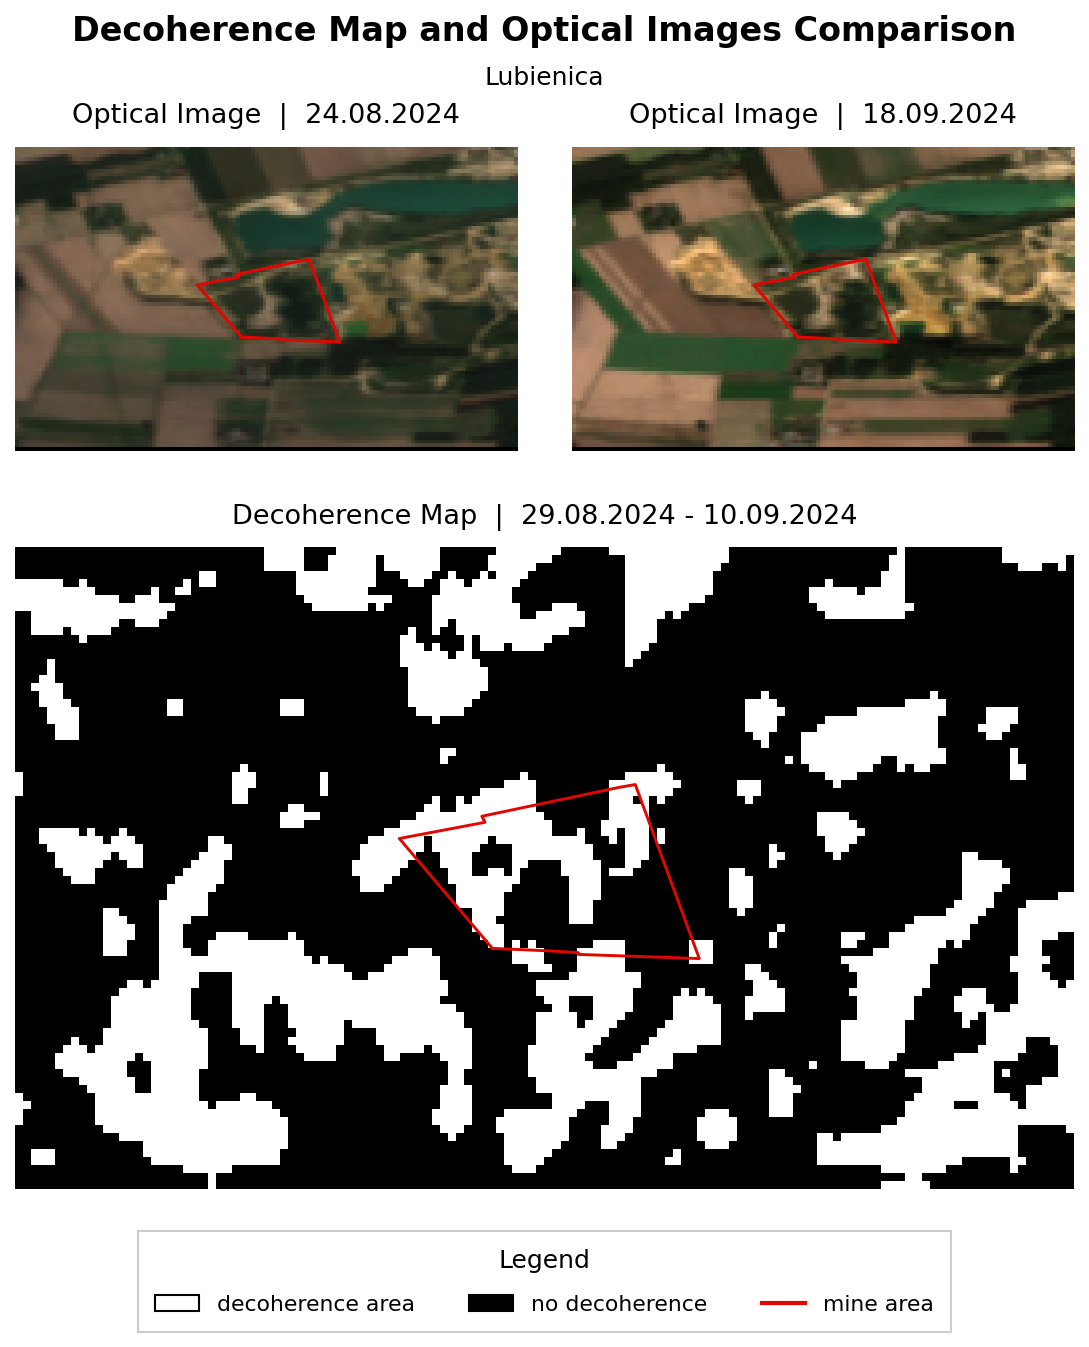

Download: S1A_IW_SLC__1SDV_20240922T045246_20240922T045314_055773_06D044_33C3.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20240922T045246_20240922T045314_055773_06D044_33C3.zip (4.61 GB)
Pair 12/17  S1A_IW_SLC__1SDV_20240910T045246_20240910T045313_055598_06C964_74ED.zip  x  S1A_IW_SLC__1SDV_20240922T045246_20240922T045314_055773_06D044_33C3.zip
Opening:  S1A_IW_SLC__1SDV_20240910T045246_20240910T045313_055598_06C964_74ED
Opening:  S1A_IW_SLC__1SDV_20240922T045246_20240922T045314_055773_06D044_33C3
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler T

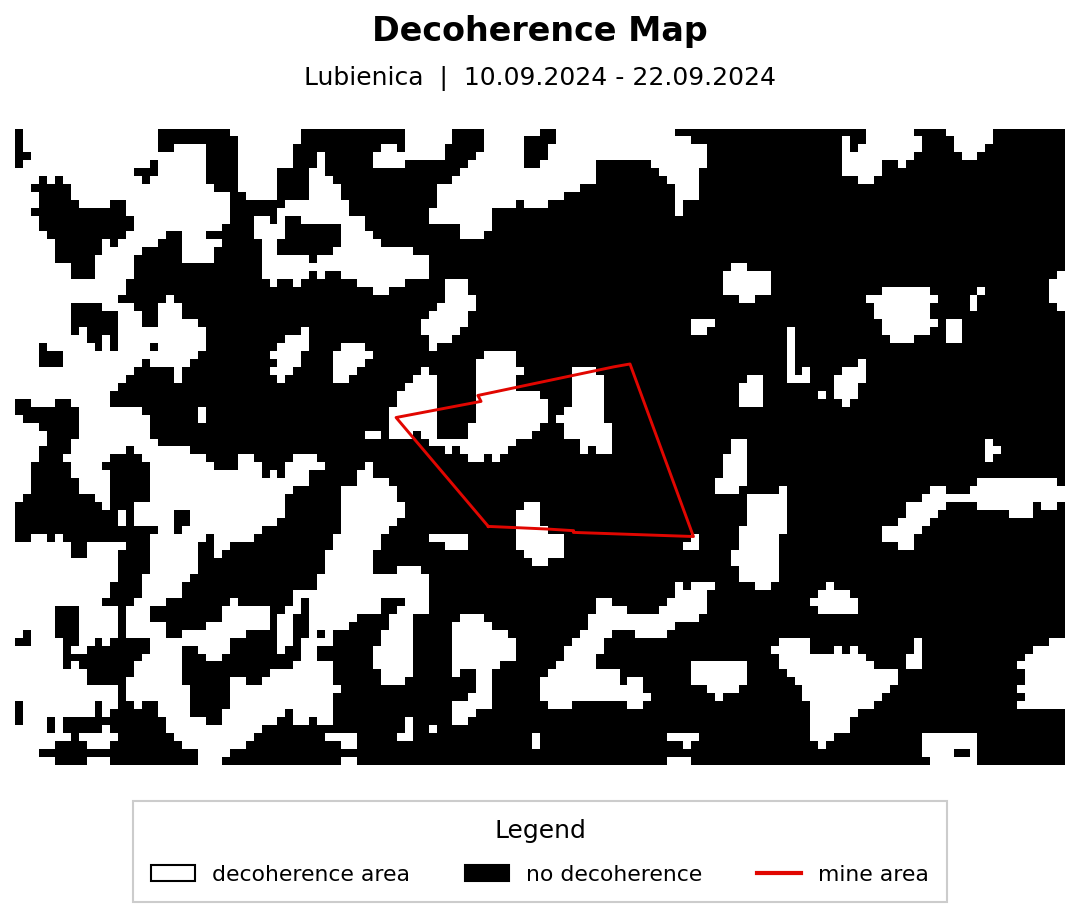

Searching for Sentinel-2 images ...
  date range: 2024-08-10 - 2024-09-09
  images found: 26
  reject: 2024-08-11 20240811T093549_20240811T094151_T34UED, clouds cover AOI
  reject: 2024-08-11 20240811T093549_20240811T094151_T34UDD, clouds cover AOI
  accept: 2024-08-14 20240814T094549_20240814T095005_T34UED
  accept: 2024-08-14 20240814T094549_20240814T095005_T34UDD
  accept: 2024-08-16 20240816T094031_20240816T094032_T34UED
  accept: 2024-08-16 20240816T094031_20240816T094032_T34UDD
  reject: 2024-08-19 20240819T095031_20240819T095027_T34UED, clouds cover AOI
  reject: 2024-08-19 20240819T095031_20240819T095027_T34UDD, clouds cover AOI
  reject: 2024-08-21 20240821T093549_20240821T094451_T34UED, clouds cover AOI
  reject: 2024-08-21 20240821T093549_20240821T094451_T34UDD, clouds cover AOI
  accept: 2024-08-24 20240824T094549_20240824T094545_T34UED
  accept: 2024-08-24 20240824T094549_20240824T094545_T34UDD
  accept: 2024-08-24 20240824T094549_20240824T095551_T34UED
  accept: 2024-08-2

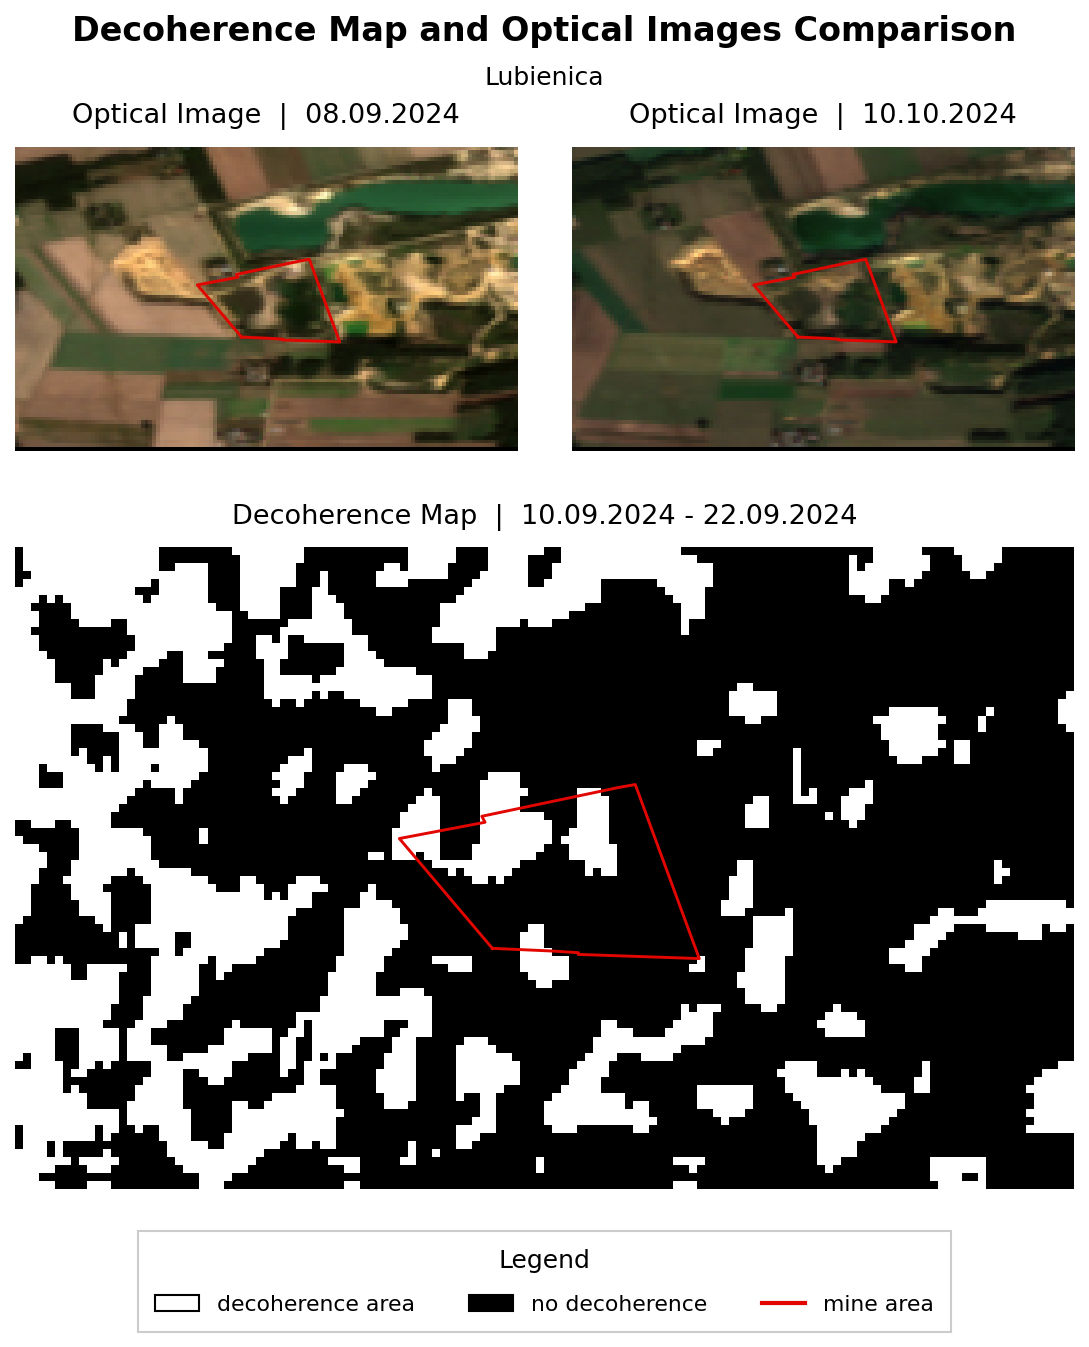

Download: S1A_IW_SLC__1SDV_20241004T045247_20241004T045314_055948_06D73B_937F.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20241004T045247_20241004T045314_055948_06D73B_937F.zip (4.74 GB)
Pair 13/17  S1A_IW_SLC__1SDV_20240922T045246_20240922T045314_055773_06D044_33C3.zip  x  S1A_IW_SLC__1SDV_20241004T045247_20241004T045314_055948_06D73B_937F.zip
Opening:  S1A_IW_SLC__1SDV_20240922T045246_20240922T045314_055773_06D044_33C3
Opening:  S1A_IW_SLC__1SDV_20241004T045247_20241004T045314_055948_06D73B_937F
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler T

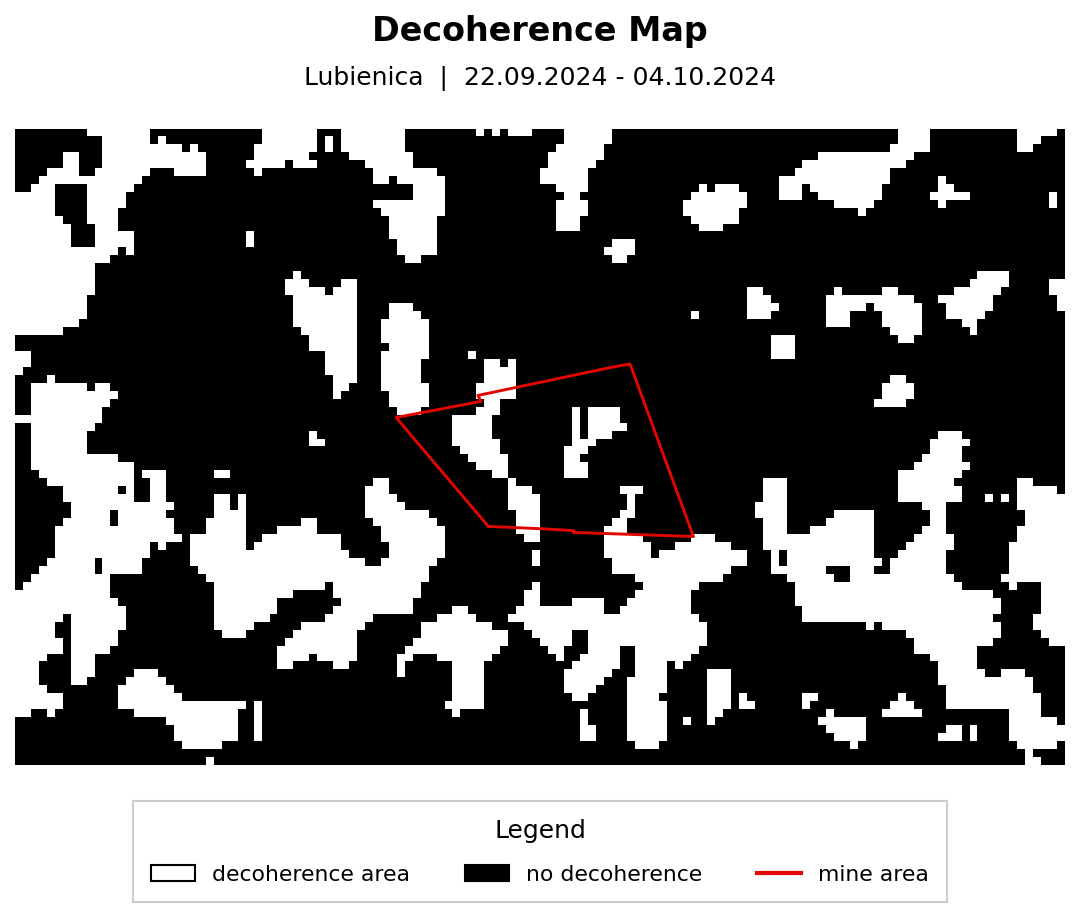

Searching for Sentinel-2 images ...
  date range: 2024-08-22 - 2024-09-21
  images found: 26
  accept: 2024-08-24 20240824T094549_20240824T094545_T34UED
  accept: 2024-08-24 20240824T094549_20240824T094545_T34UDD
  accept: 2024-08-24 20240824T094549_20240824T095551_T34UED
  accept: 2024-08-24 20240824T094549_20240824T095551_T34UDD
  reject: 2024-08-26 20240826T094031_20240826T094028_T34UED, clouds cover AOI
  reject: 2024-08-26 20240826T094031_20240826T094028_T34UDD, clouds cover AOI
  accept: 2024-08-29 20240829T095031_20240829T095026_T34UED
  accept: 2024-08-29 20240829T095031_20240829T095026_T34UDD
  reject: 2024-08-31 20240831T093549_20240831T093823_T34UED, clouds cover AOI
  reject: 2024-08-31 20240831T093549_20240831T093823_T34UDD, clouds cover AOI
  reject: 2024-09-03 20240903T094549_20240903T095323_T34UED, clouds cover AOI
  reject: 2024-09-03 20240903T094549_20240903T095323_T34UDD, clouds cover AOI
  reject: 2024-09-05 20240905T094031_20240905T094031_T34UED, clouds cover AOI
 

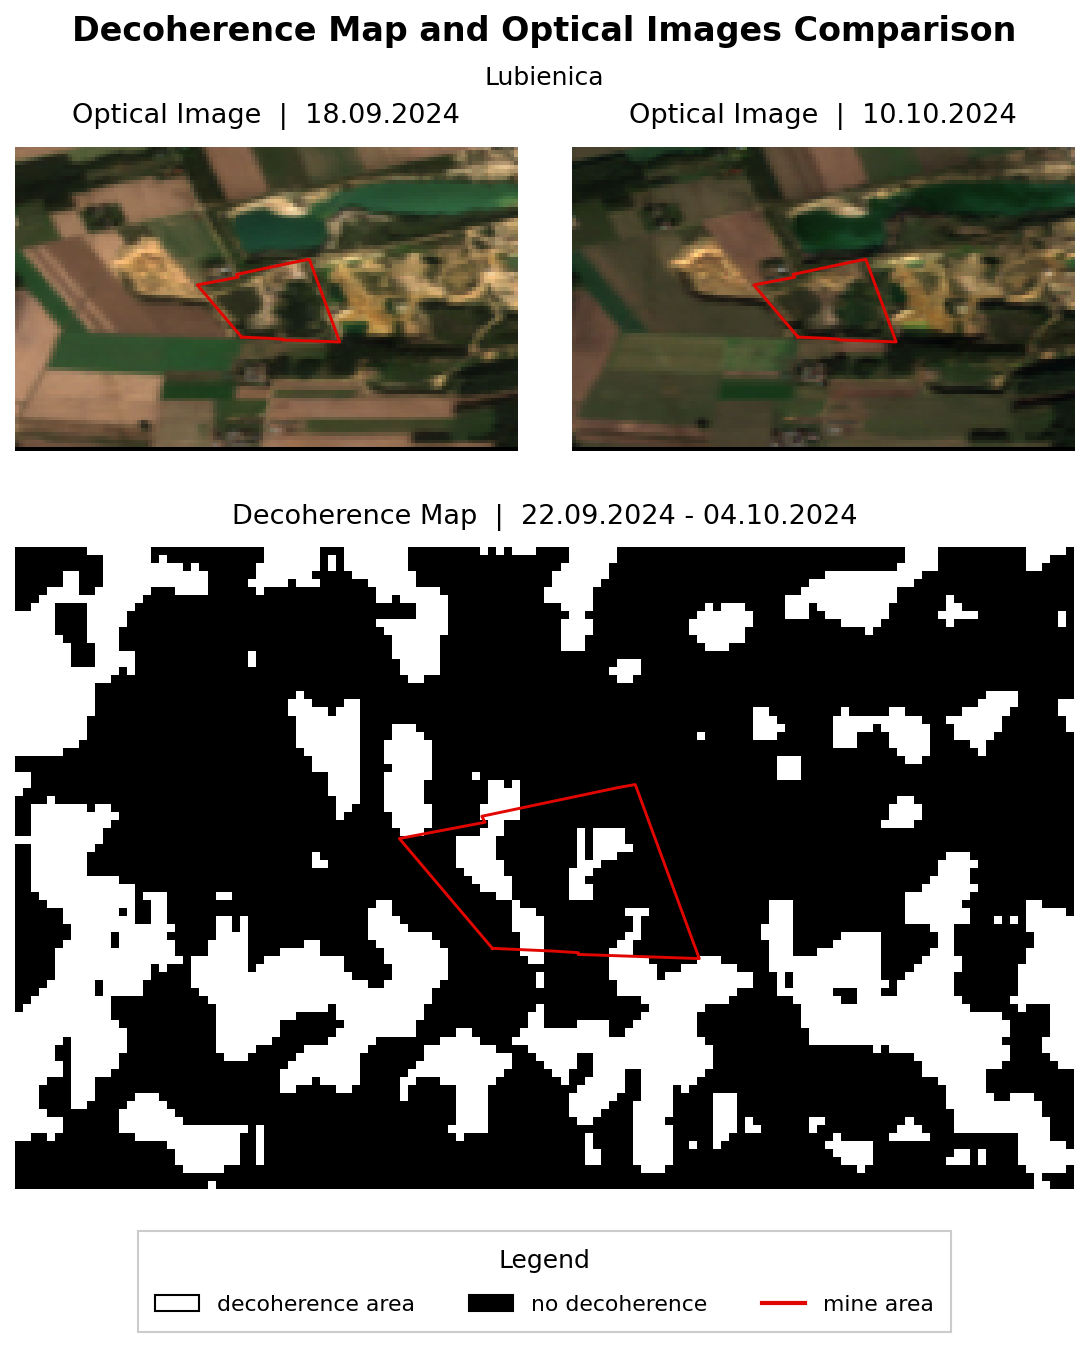

Download: S1A_IW_SLC__1SDV_20241016T045247_20241016T045314_056123_06DE18_E7C4.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20241016T045247_20241016T045314_056123_06DE18_E7C4.zip (4.63 GB)
Pair 14/17  S1A_IW_SLC__1SDV_20241004T045247_20241004T045314_055948_06D73B_937F.zip  x  S1A_IW_SLC__1SDV_20241016T045247_20241016T045314_056123_06DE18_E7C4.zip
Opening:  S1A_IW_SLC__1SDV_20241004T045247_20241004T045314_055948_06D73B_937F
Opening:  S1A_IW_SLC__1SDV_20241016T045247_20241016T045314_056123_06DE18_E7C4
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler T

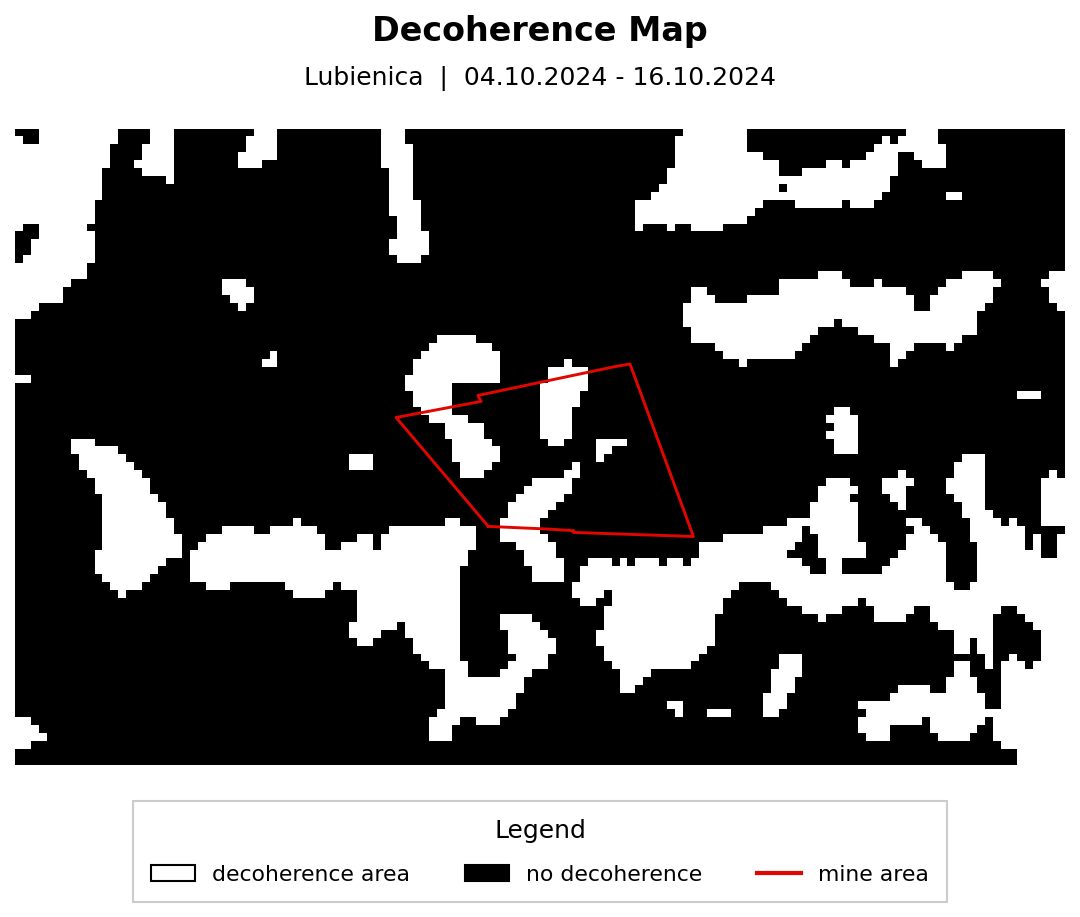

Searching for Sentinel-2 images ...
  date range: 2024-09-04 - 2024-10-03
  images found: 24
  reject: 2024-09-05 20240905T094031_20240905T094031_T34UED, clouds cover AOI
  reject: 2024-09-05 20240905T094031_20240905T094031_T34UDD, clouds cover AOI
  accept: 2024-09-08 20240908T095031_20240908T095523_T34UED
  accept: 2024-09-08 20240908T095031_20240908T095523_T34UDD
  reject: 2024-09-10 20240910T094029_20240910T094445_T34UED, clouds cover AOI
  reject: 2024-09-10 20240910T094029_20240910T094445_T34UDD, clouds cover AOI
  reject: 2024-09-13 20240913T095029_20240913T095104_T34UED, clouds cover AOI
  reject: 2024-09-13 20240913T095029_20240913T095104_T34UDD, clouds cover AOI
  reject: 2024-09-15 20240915T094031_20240915T094048_T34UED, clouds cover AOI
  reject: 2024-09-15 20240915T094031_20240915T094048_T34UDD, clouds cover AOI
  accept: 2024-09-18 20240918T095031_20240918T095028_T34UED
  accept: 2024-09-18 20240918T095031_20240918T095028_T34UDD
  reject: 2024-09-20 20240920T094029_202409

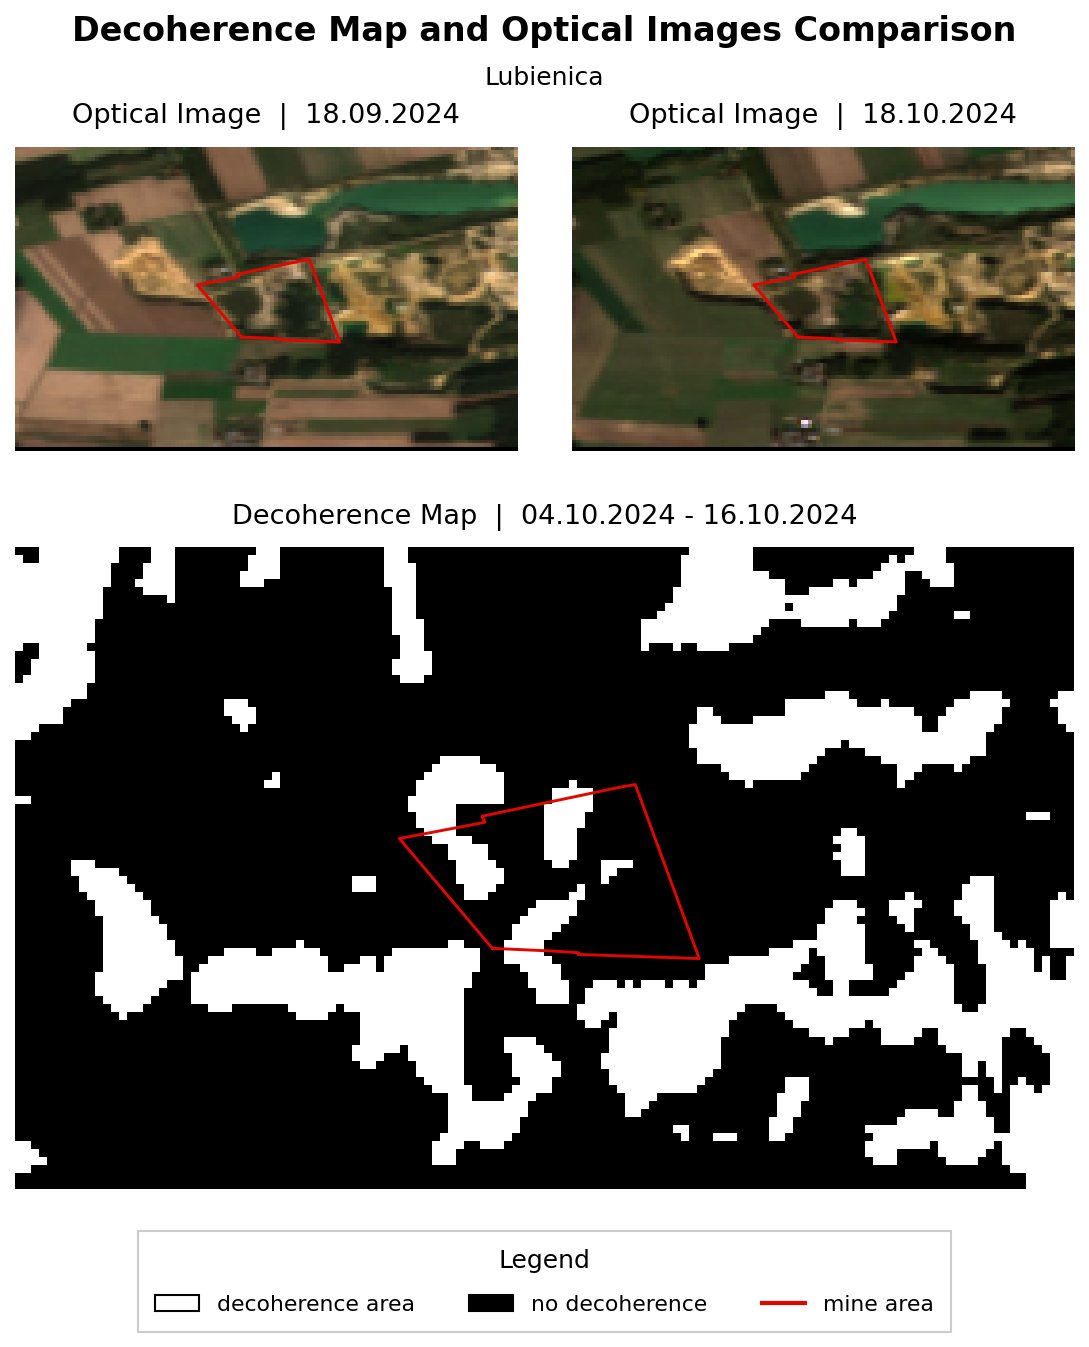

Download: S1A_IW_SLC__1SDV_20241028T045247_20241028T045314_056298_06E50B_FD45.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20241028T045247_20241028T045314_056298_06E50B_FD45.zip (4.60 GB)
Pair 15/17  S1A_IW_SLC__1SDV_20241016T045247_20241016T045314_056123_06DE18_E7C4.zip  x  S1A_IW_SLC__1SDV_20241028T045247_20241028T045314_056298_06E50B_FD45.zip
Opening:  S1A_IW_SLC__1SDV_20241016T045247_20241016T045314_056123_06DE18_E7C4
Opening:  S1A_IW_SLC__1SDV_20241028T045247_20241028T045314_056298_06E50B_FD45
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler T

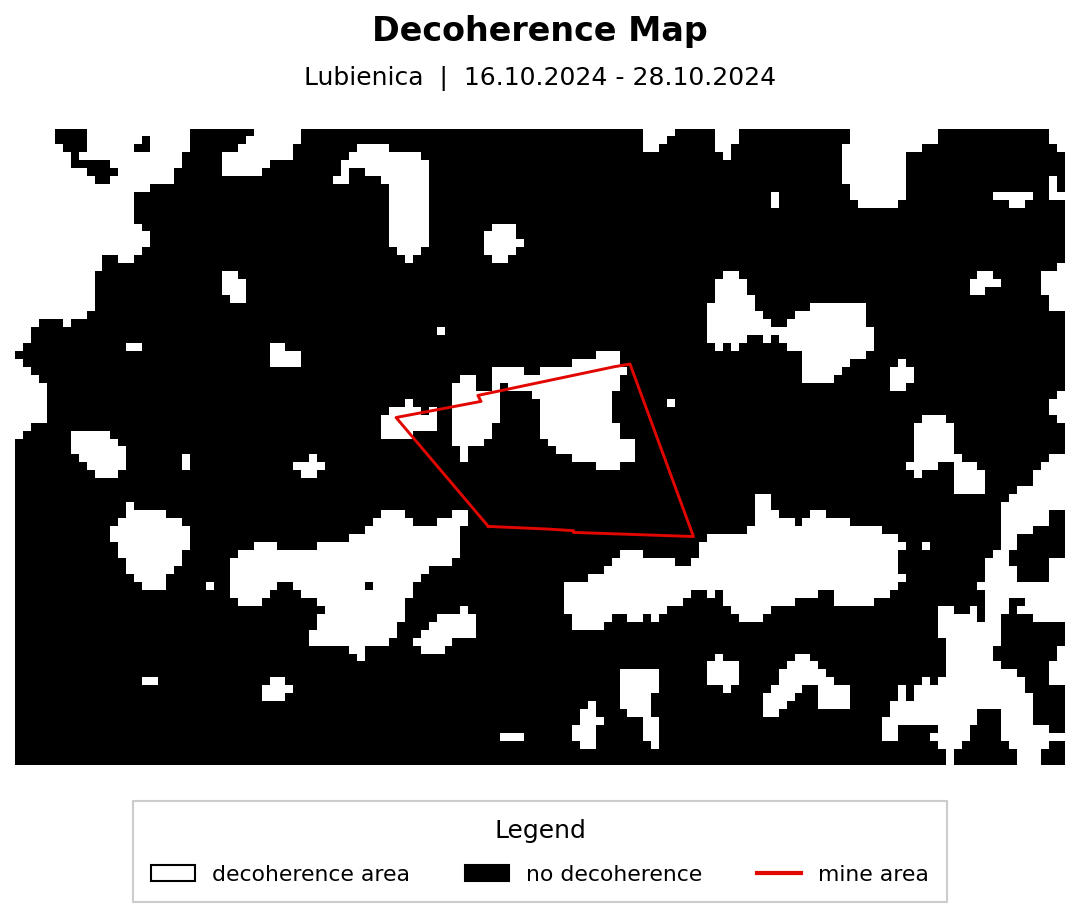

Searching for Sentinel-2 images ...
  date range: 2024-09-16 - 2024-10-15
  images found: 24
  accept: 2024-09-18 20240918T095031_20240918T095028_T34UED
  accept: 2024-09-18 20240918T095031_20240918T095028_T34UDD
  reject: 2024-09-20 20240920T094029_20240920T094449_T34UED, clouds cover AOI
  reject: 2024-09-20 20240920T094029_20240920T094449_T34UDD, clouds cover AOI
  reject: 2024-09-23 20240923T095029_20240923T095340_T34UED, clouds cover AOI
  reject: 2024-09-23 20240923T095029_20240923T095340_T34UDD, clouds cover AOI
  reject: 2024-09-25 20240925T094031_20240925T094108_T34UED, clouds cover AOI
  reject: 2024-09-25 20240925T094031_20240925T094108_T34UDD, clouds cover AOI
  reject: 2024-09-28 20240928T095031_20240928T095055_T34UED, clouds cover AOI
  reject: 2024-09-28 20240928T095031_20240928T095055_T34UDD, clouds cover AOI
  reject: 2024-09-30 20240930T094029_20240930T094136_T34UED, clouds cover AOI
  reject: 2024-09-30 20240930T094029_20240930T094136_T34UDD, clouds cover AOI
  rejec

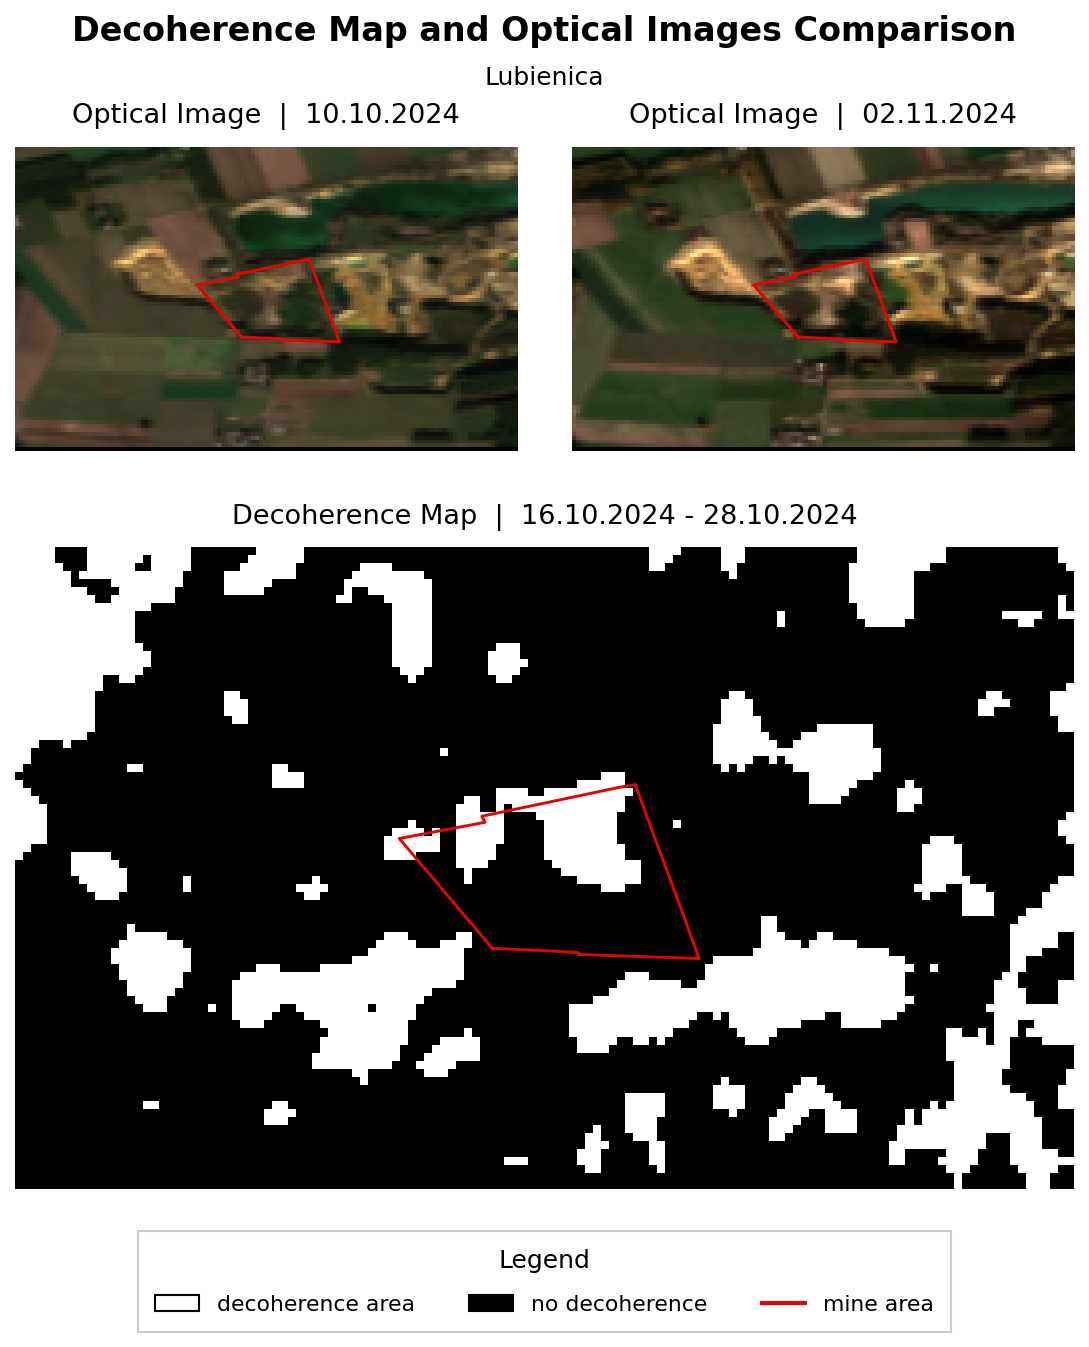

Download: S1A_IW_SLC__1SDV_20241109T045247_20241109T045314_056473_06EBF8_A658.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20241109T045247_20241109T045314_056473_06EBF8_A658.zip (4.59 GB)
Pair 16/17  S1A_IW_SLC__1SDV_20241028T045247_20241028T045314_056298_06E50B_FD45.zip  x  S1A_IW_SLC__1SDV_20241109T045247_20241109T045314_056473_06EBF8_A658.zip
Opening:  S1A_IW_SLC__1SDV_20241028T045247_20241028T045314_056298_06E50B_FD45
Opening:  S1A_IW_SLC__1SDV_20241109T045247_20241109T045314_056473_06EBF8_A658
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler T

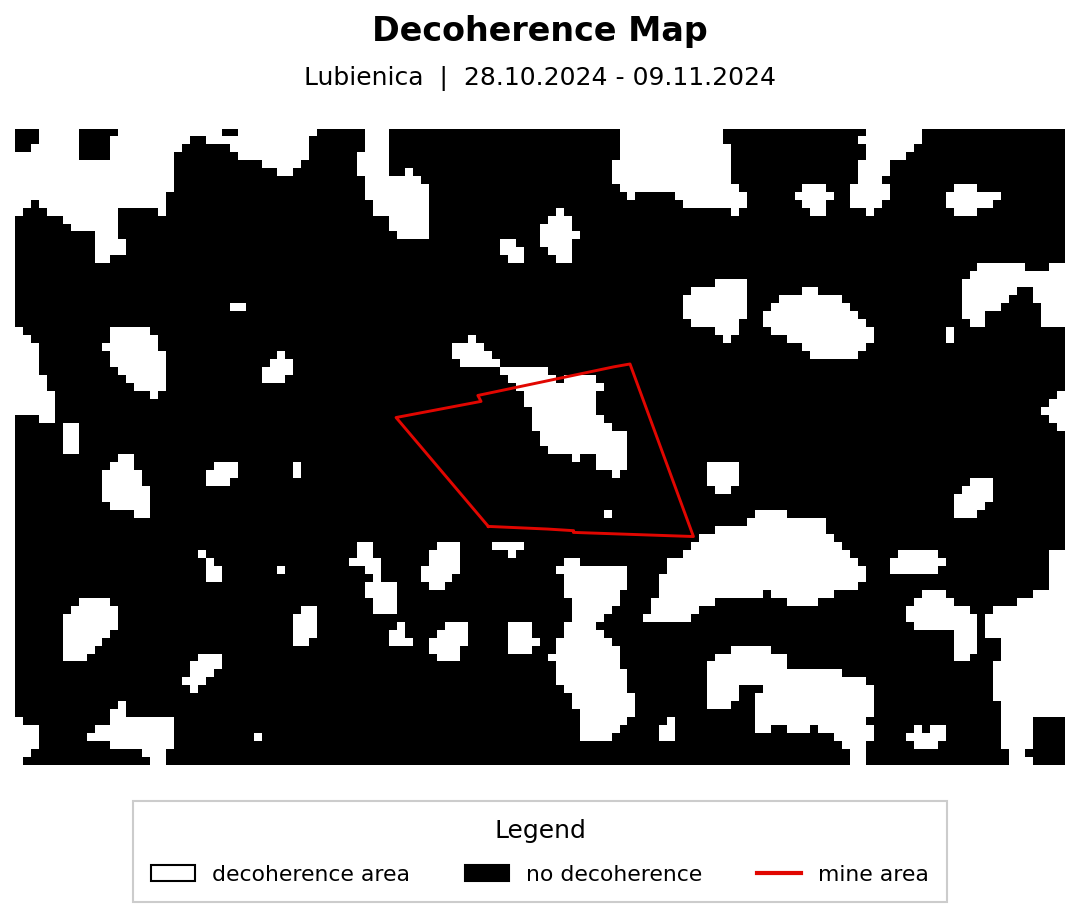

Searching for Sentinel-2 images ...
  date range: 2024-09-28 - 2024-10-27
  images found: 24
  reject: 2024-09-28 20240928T095031_20240928T095055_T34UED, clouds cover AOI
  reject: 2024-09-28 20240928T095031_20240928T095055_T34UDD, clouds cover AOI
  reject: 2024-09-30 20240930T094029_20240930T094136_T34UED, clouds cover AOI
  reject: 2024-09-30 20240930T094029_20240930T094136_T34UDD, clouds cover AOI
  reject: 2024-10-03 20241003T095029_20241003T095133_T34UED, clouds cover AOI
  reject: 2024-10-03 20241003T095029_20241003T095133_T34UDD, clouds cover AOI
  reject: 2024-10-05 20241005T094031_20241005T094219_T34UED, clouds cover AOI
  reject: 2024-10-05 20241005T094031_20241005T094219_T34UDD, clouds cover AOI
  reject: 2024-10-08 20241008T095031_20241008T095200_T34UED, clouds cover AOI
  reject: 2024-10-08 20241008T095031_20241008T095200_T34UDD, clouds cover AOI
  accept: 2024-10-10 20241010T094029_20241010T094028_T34UED
  accept: 2024-10-10 20241010T094029_20241010T094028_T34UDD
  rejec

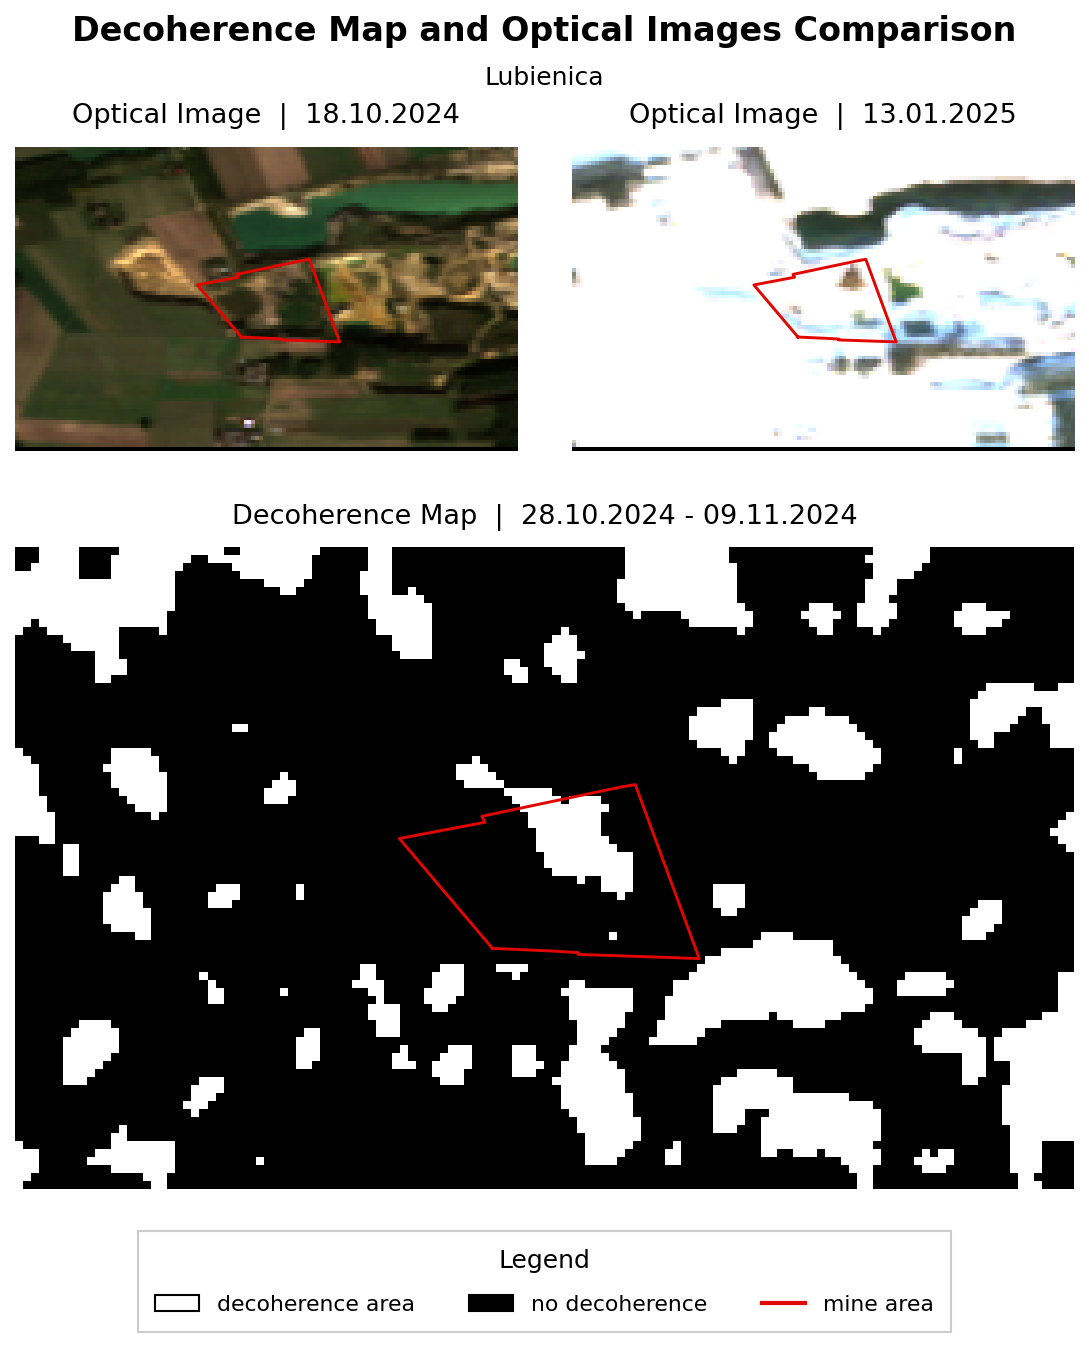

Download: S1A_IW_SLC__1SDV_20241121T045246_20241121T045313_056648_06F302_689F.zip ...
  File is already downloaded: C:\space_technologies\Kopalnie\open-pit-mining\sar\safe_downloads\S1A_IW_SLC__1SDV_20241121T045246_20241121T045313_056648_06F302_689F.zip (4.62 GB)
Pair 17/17  S1A_IW_SLC__1SDV_20241109T045247_20241109T045314_056473_06EBF8_A658.zip  x  S1A_IW_SLC__1SDV_20241121T045246_20241121T045313_056648_06F302_689F.zip
Opening:  S1A_IW_SLC__1SDV_20241109T045247_20241109T045314_056473_06EBF8_A658
Opening:  S1A_IW_SLC__1SDV_20241121T045246_20241121T045313_056648_06F302_689F
Apply Orbit File ...
Apply Orbit File ...
  subswaths: IW1, IW2
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 TOPS Split ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
S-1 Back-Geocoding: Copernicus 30m, bilinear ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
Coherence Estimation: Copernicus 30m, window 5x5 ...
S-1 TOPS Deburst ...
S-1 TOPS Deburst ...
S-1 TOPS Merge ...
Range-Doppler T

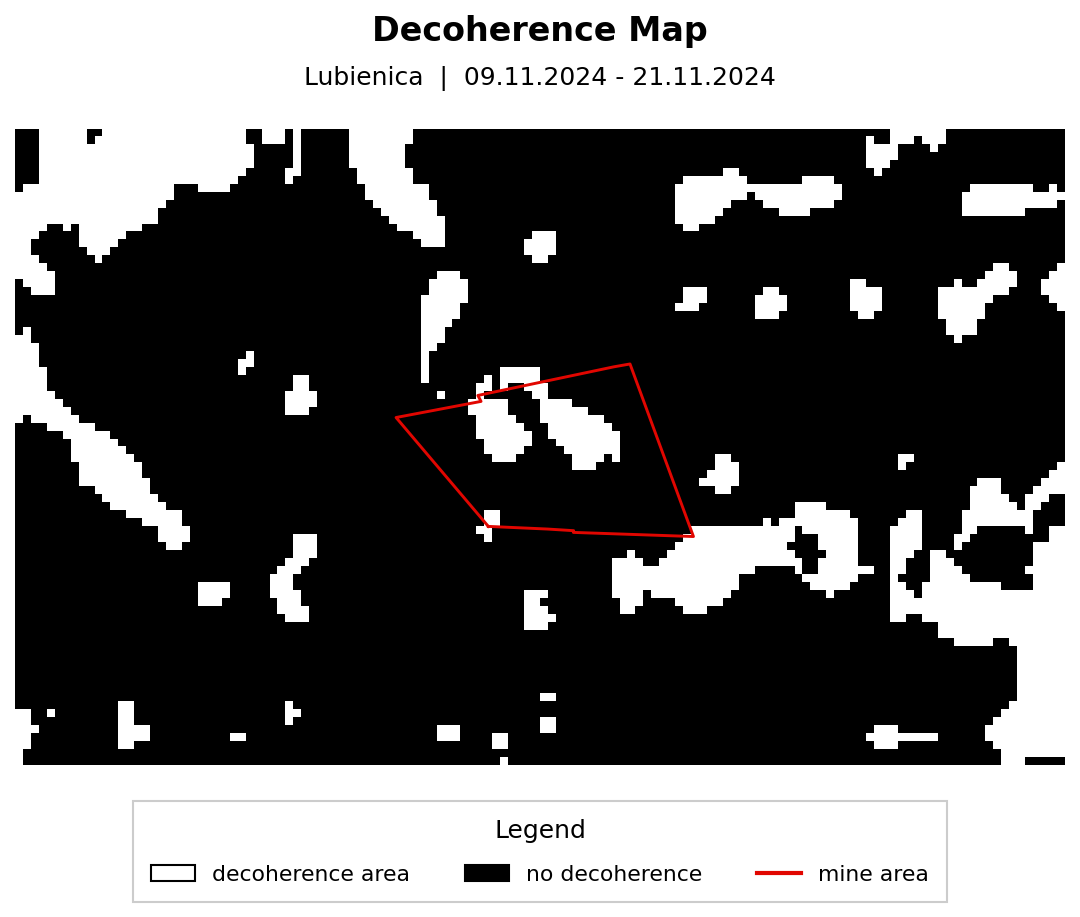

Searching for Sentinel-2 images ...
  date range: 2024-10-09 - 2024-11-08
  images found: 24
  accept: 2024-10-10 20241010T094029_20241010T094028_T34UED
  accept: 2024-10-10 20241010T094029_20241010T094028_T34UDD
  reject: 2024-10-13 20241013T095029_20241013T095026_T34UED, clouds cover AOI
  reject: 2024-10-13 20241013T095029_20241013T095026_T34UDD, clouds cover AOI
  reject: 2024-10-15 20241015T094031_20241015T094320_T34UED, clouds cover AOI
  reject: 2024-10-15 20241015T094031_20241015T094320_T34UDD, clouds cover AOI
  accept: 2024-10-18 20241018T095031_20241018T095240_T34UED
  accept: 2024-10-18 20241018T095031_20241018T095240_T34UDD
  reject: 2024-10-20 20241020T094029_20241020T094031_T34UED, clouds cover AOI
  reject: 2024-10-20 20241020T094029_20241020T094031_T34UDD, clouds cover AOI
  reject: 2024-10-23 20241023T095029_20241023T095028_T34UED, clouds cover AOI
  reject: 2024-10-23 20241023T095029_20241023T095028_T34UDD, clouds cover AOI
  reject: 2024-10-25 20241025T094101_202410

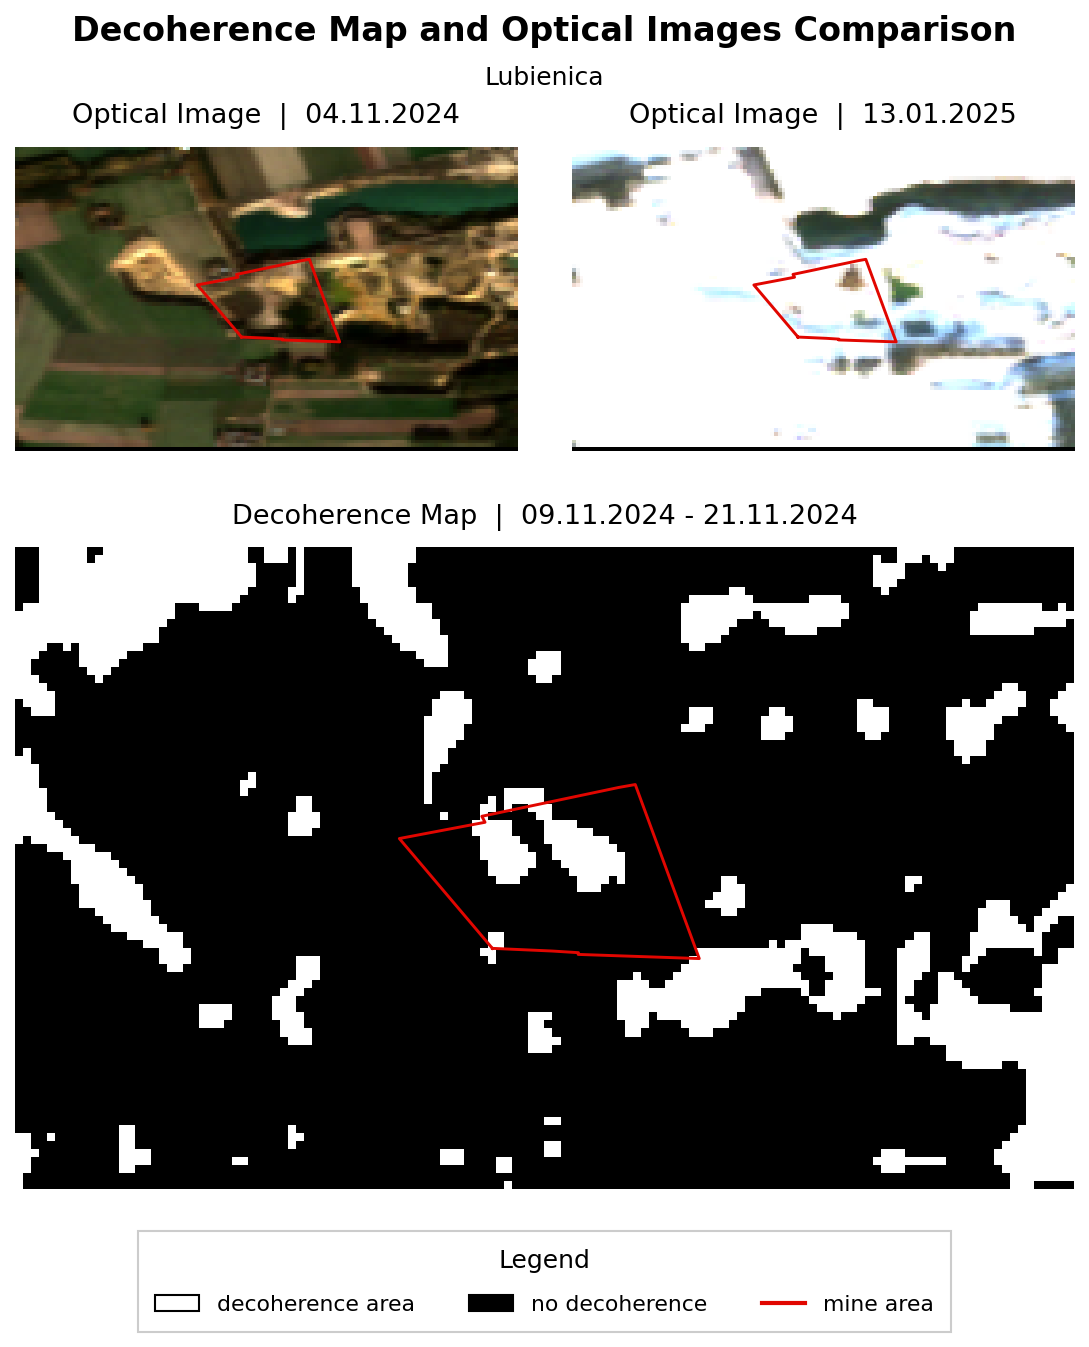

Saved GIF: c:\space_technologies\Kopalnie\open-pit-mining\sar\output_decoherence_maps\decoherence_maps.gif


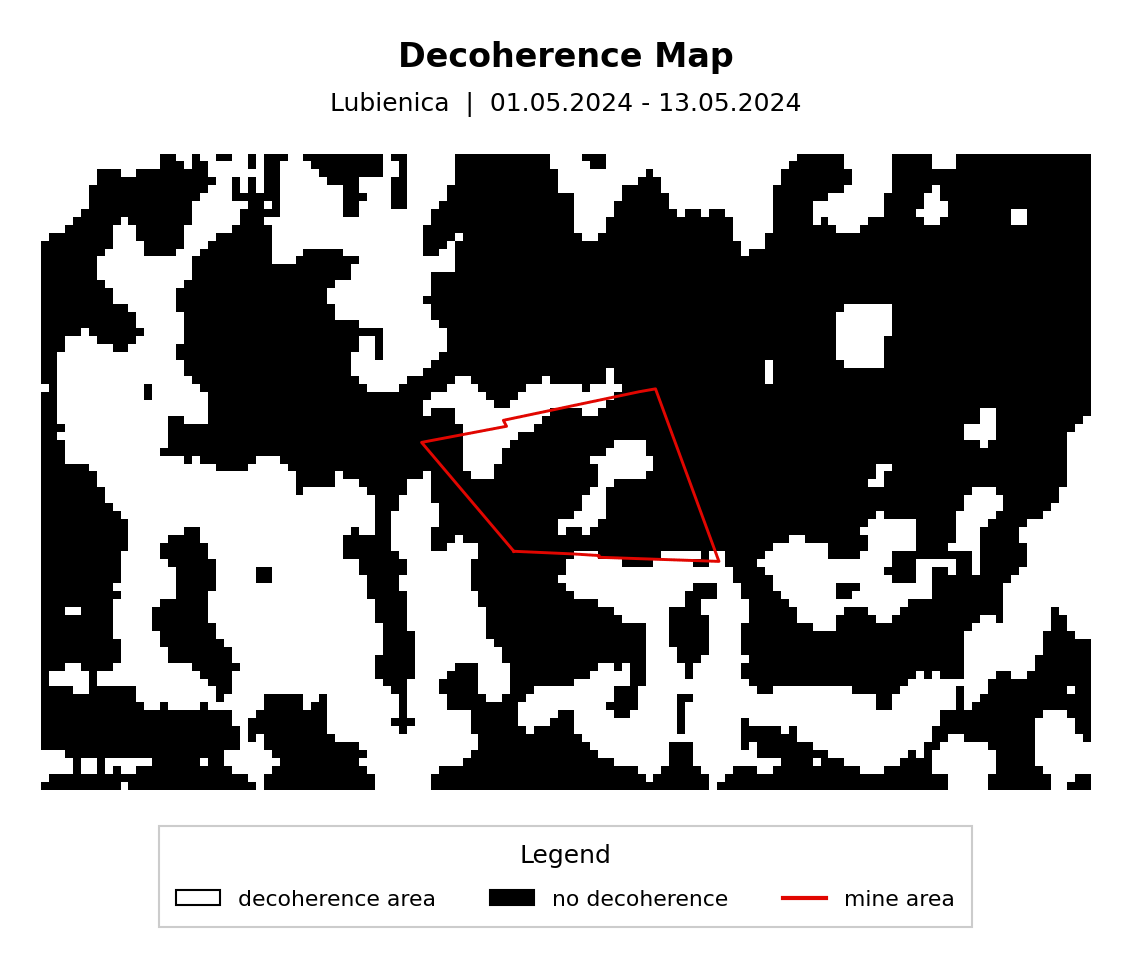

In [23]:
def decoherence_analysis(master_zip, slave_zip, mine):
    master_slc = open_slc(master_zip)
    slave_slc = open_slc(slave_zip)

    master_orb = apply_orbit_file(master_slc)
    slave_orb = apply_orbit_file(slave_slc)

    subswath = choose_subswaths_for_aoi(master_orb)

    master_orb_split = { swath: topsar_split(master_orb, swath) for swath in subswath }
    slave_orb_split = { swath: topsar_split(slave_orb, swath) for swath in subswath }

    orb_split_stack = { swath: back_geocoding(master_orb_split[swath], slave_orb_split[swath]) for swath in subswath }
    orb_split_stack_coherence = { swath: coherence_estimation(orb_split_stack[swath]) for swath in subswath }
    orb_split_stack_coherence_deburst = { swath: topsar_deburst(orb_split_stack_coherence[swath]) for swath in subswath }

    if len(orb_split_stack_coherence_deburst) > 1:
        coherence_map = topsar_merge([orb_split_stack_coherence_deburst[swath] for swath in subswath])
    else:
        coherence_map = orb_split_stack_coherence_deburst[subswath[0]]

    coherence_map_tc = terrain_correction(coherence_map)
    coherence_map_tc_subset = subset(coherence_map_tc)
    extent = _scene_extent(coherence_map_tc_subset)

    decoherence_map = otsu_treshold(coherence_map_tc_subset)
    
    decoherence_map_water = water_mask(decoherence_map, extent, master_zip, slave_zip)
    decoherence_map_water_median = median_filtering(decoherence_map_water)

    opened = [
        master_slc, slave_slc, master_orb, slave_orb,
        *master_orb_split.values(), *slave_orb_split.values(),
        *orb_split_stack.values(), 
        *orb_split_stack_coherence.values(), 
        *orb_split_stack_coherence_deburst.values(),
        coherence_map, coherence_map_tc, coherence_map_tc_subset,
    ]
    close_products(opened)

    return decoherence_map_water_median, extent

mine = shape(json.loads(POLYGON_PATH.read_text(encoding="utf-8"))["features"][0]["geometry"])
AOI = make_polygon_buffer(POLYGON_PATH)
scenes_stack = find_sentinel_1_scenes()

session = start_asf_session()
master = download_images(scenes_stack[0], session)
slave = download_images(scenes_stack[1], session)

saved_maps = []
for scene in range(len(scenes_stack) - 1):
    print("Pair %d/%d  %s  x  %s" % (scene + 1, len(scenes_stack) - 1, master.name, slave.name))

    decoherence_map, extent = decoherence_analysis(master, slave, mine)
    print("SAR analysis done.")
    
    output_map = visualization(decoherence_map, mine, master, slave, extent)
    saved_maps.append(output_map)
    visualization_with_sentinel(decoherence_map, mine, master, slave, extent)

    # remove_scene(master)

    if scene + 2 < len(scenes_stack):
        master = slave
        slave = download_images(scenes_stack[scene + 2], session)

show_decoherence_gif(saved_maps)
    